# Skoki w jednej sekundzie

In [1]:
from cProfile import label

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

## Wczytanie danych

In [104]:
path = 'data/bitcoin_data.parquet'
data_raw = pq.read_pandas(path)

In [107]:
kolumny = [
    'found_at'
]

data = data_raw.select(kolumny).to_pandas()


data

,found_at
0,2025-09-09 21:40:57
1,2025-09-09 21:40:57
2,2025-09-09 21:40:57
3,2025-09-09 21:41:14
4,2025-09-09 21:41:14
...,...
11110272,2025-08-03 21:54:09
11110273,2025-08-03 21:54:09
11110274,2025-08-03 21:54:09
11110275,2025-08-03 21:54:09


In [108]:
type(data)

pandas.DataFrame

In [109]:
czasy = data['found_at']
# czasy = czasy.sort_values().reset_index(drop=True)
czasy

0          2025-09-09 21:40:57
1          2025-09-09 21:40:57
2          2025-09-09 21:40:57
3          2025-09-09 21:41:14
4          2025-09-09 21:41:14
                   ...        
11110272   2025-08-03 21:54:09
11110273   2025-08-03 21:54:09
11110274   2025-08-03 21:54:09
11110275   2025-08-03 21:54:09
11110276   2025-08-03 21:54:09
Name: found_at, Length: 11110277, dtype: datetime64[ns]

In [110]:
type(data)

pandas.DataFrame

### Czy są milisekundy?

In [101]:
# Liczba obserwacji z niezerową częścią ułamkową sekundy
podsekundowe = (
    czasy.notna() &
    (czasy != czasy.dt.floor('s'))
)

print("Transakcje z podsekundami:", podsekundowe.sum())
print("Udział:", podsekundowe.mean() * 100, "%")

# Przykładowe wartości, jeśli istnieją
print(czasy[podsekundowe].head(10))

Transakcje z podsekundami: 0
Udział: 0.0 %
Series([], Name: found_at, dtype: datetime64[ns])



Nie ma

### Ile było skokow w kazdej sekundzie

In [65]:
ile_obserwacji_w_sekundzie = czasy.value_counts()
ile_obserwacji_w_sekundzie

found_at
2025-08-11 05:49:09    321
2025-08-11 05:41:58    300
2025-08-14 21:41:17    290
2025-08-07 00:19:06    288
2025-08-11 05:40:55    285
                      ... 
2025-08-03 21:53:58      1
2025-08-03 21:54:00      1
2025-08-03 21:54:01      1
2025-08-03 21:54:02      1
2025-08-03 21:54:07      1
Name: count, Length: 2211272, dtype: int64

In [67]:
ile_obserwacji_w_sekundzie = ile_obserwacji_w_sekundzie.sort_index()
ile_obserwacji_w_sekundzie

found_at
2025-08-03 06:27:44    4
2025-08-03 06:27:45    2
2025-08-03 06:27:46    3
2025-08-03 06:27:47    5
2025-08-03 06:27:48    1
                      ..
2025-10-09 20:44:15    7
2025-10-09 20:44:16    1
2025-10-09 20:44:17    1
2025-10-09 20:44:19    2
2025-10-09 20:44:20    1
Name: count, Length: 2211272, dtype: int64

In [85]:
type(ile_obserwacji_w_sekundzie.index)

pandas.DatetimeIndex

# Analiza kawałka danych

In [86]:
start = pd.Timestamp('2025-08-11 05:45:00')
end = pd.Timestamp('2025-08-11 05:55:00')

df_filtered = ile_obserwacji_w_sekundzie.loc[start:end]
df_filtered

found_at
2025-08-11 05:45:00    4
2025-08-11 05:45:01    4
2025-08-11 05:45:02    1
2025-08-11 05:45:03    2
2025-08-11 05:45:04    4
                      ..
2025-08-11 05:54:55    1
2025-08-11 05:54:56    2
2025-08-11 05:54:57    1
2025-08-11 05:54:58    1
2025-08-11 05:54:59    4
Name: count, Length: 445, dtype: int64

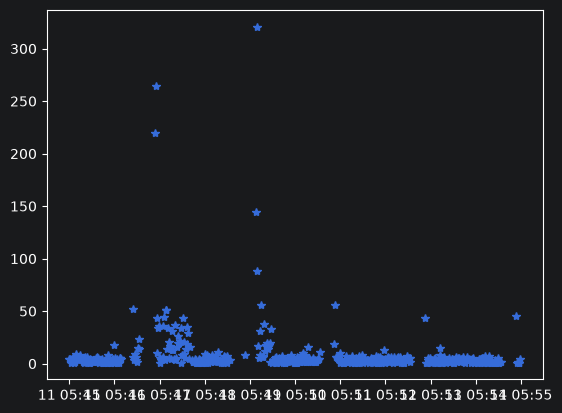

In [87]:
plt.plot(df_filtered, "*")

In [90]:
mask = df_filtered > 50

mask = (
    mask
    | mask.shift(-1, fill_value=False)
    | mask.shift(-2, fill_value=False)
    | mask.shift(-3, fill_value=False)
)

df_filtered3 = df_filtered.loc[mask]
df_filtered3

found_at
2025-08-11 05:46:07      5
2025-08-11 05:46:08      5
2025-08-11 05:46:09      4
2025-08-11 05:46:24     52
2025-08-11 05:46:31     15
2025-08-11 05:46:32     23
2025-08-11 05:46:33     14
2025-08-11 05:46:54    220
2025-08-11 05:46:55    264
2025-08-11 05:47:05      6
2025-08-11 05:47:06     44
2025-08-11 05:47:07      3
2025-08-11 05:47:08     51
2025-08-11 05:47:09     51
2025-08-11 05:48:31      3
2025-08-11 05:48:33      3
2025-08-11 05:48:53      8
2025-08-11 05:49:08    144
2025-08-11 05:49:09    321
2025-08-11 05:49:10     88
2025-08-11 05:49:12      5
2025-08-11 05:49:13     31
2025-08-11 05:49:14      8
2025-08-11 05:49:15     56
2025-08-11 05:50:32      4
2025-08-11 05:50:33     11
2025-08-11 05:50:52     19
2025-08-11 05:50:53     56
Name: count, dtype: int64

In [97]:
start = pd.Timestamp('2025-08-11 05:46:00')
end = pd.Timestamp('2025-08-11 05:46:59')

to_plot = df_filtered.loc[start:end]
to_plot

found_at
2025-08-11 05:46:00     18
2025-08-11 05:46:01      5
2025-08-11 05:46:02      3
2025-08-11 05:46:03      4
2025-08-11 05:46:04      1
2025-08-11 05:46:06      1
2025-08-11 05:46:07      5
2025-08-11 05:46:08      5
2025-08-11 05:46:09      4
2025-08-11 05:46:24     52
2025-08-11 05:46:25      6
2025-08-11 05:46:26      3
2025-08-11 05:46:27      9
2025-08-11 05:46:28      3
2025-08-11 05:46:29      6
2025-08-11 05:46:30      2
2025-08-11 05:46:31     15
2025-08-11 05:46:32     23
2025-08-11 05:46:33     14
2025-08-11 05:46:54    220
2025-08-11 05:46:55    264
2025-08-11 05:46:56     10
2025-08-11 05:46:57     43
2025-08-11 05:46:58     34
2025-08-11 05:46:59     36
Name: count, dtype: int64

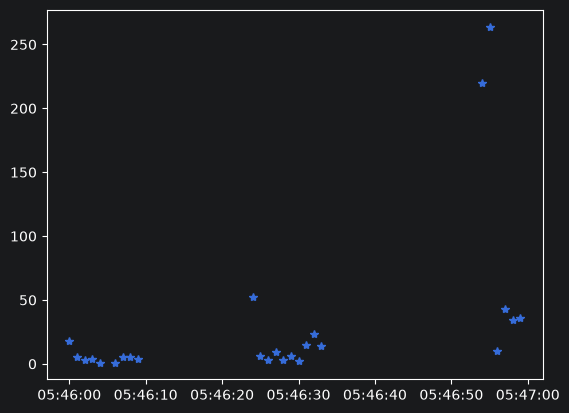

In [ ]:
plt.plot(to_plot, "*")
plt.show()

Inny okres

In [119]:
start = pd.Timestamp('2025-08-11 05:54:00')
end = pd.Timestamp('2025-08-11 05:55:00')

to_plot = df_filtered.loc[start:end]
to_plot

found_at
2025-08-11 05:54:00     2
2025-08-11 05:54:02     1
2025-08-11 05:54:03     1
2025-08-11 05:54:04     4
2025-08-11 05:54:05     2
2025-08-11 05:54:06     4
2025-08-11 05:54:07     3
2025-08-11 05:54:08     5
2025-08-11 05:54:09     1
2025-08-11 05:54:10     5
2025-08-11 05:54:11     1
2025-08-11 05:54:12     7
2025-08-11 05:54:14     3
2025-08-11 05:54:15     1
2025-08-11 05:54:16     1
2025-08-11 05:54:17     7
2025-08-11 05:54:18     5
2025-08-11 05:54:19     2
2025-08-11 05:54:20     1
2025-08-11 05:54:22     2
2025-08-11 05:54:23     1
2025-08-11 05:54:24     1
2025-08-11 05:54:25     3
2025-08-11 05:54:26     2
2025-08-11 05:54:27     1
2025-08-11 05:54:28     2
2025-08-11 05:54:29     1
2025-08-11 05:54:30     5
2025-08-11 05:54:31     1
2025-08-11 05:54:32     2
2025-08-11 05:54:33     2
2025-08-11 05:54:53    45
2025-08-11 05:54:55     1
2025-08-11 05:54:56     2
2025-08-11 05:54:57     1
2025-08-11 05:54:58     1
2025-08-11 05:54:59     4
Name: count, dtype: int64

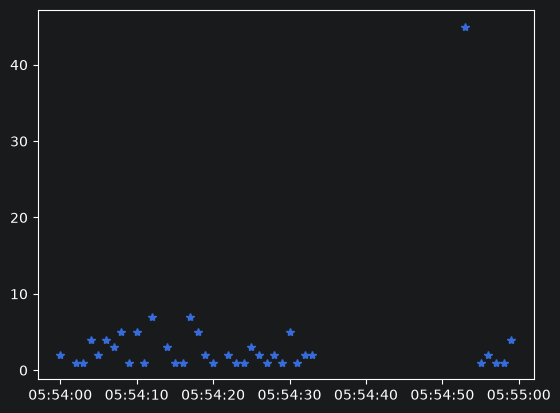

In [120]:
plt.plot(to_plot, "*")
plt.show()

bTak jak widzimy, dane nie są zbierane przez okres 21 sekund, następnie są zbierane na bardzo dużej górce. Z tego co widzę, prawie zawsze jest przerwa w zbieraniu danych przed dużym skokiem. Najprawdopodobniej procesor przestaje obsługiwać dane a potem zaciąga wszystko z bufora i przypisuje tym danym konretny czas zapisu na dysk

In [145]:
s = ile_obserwacji_w_sekundzie

import pandas as pd

s = ile_obserwacji_w_sekundzie.sort_index()

wyniki = pd.DataFrame({
    'liczba_transakcji': s,
    'poprzedni_czas': s.index.to_series().shift(1),
    'roznica_sekund': (
        s.index.to_series().diff().dt.total_seconds()
    )
})

# Wybieramy dopiero teraz wartości > 100
wyniki = wyniki[wyniki['liczba_transakcji'] > 100]

wyniki

,liczba_transakcji,poprzedni_czas,roznica_sekund
found_at,,,
2025-08-03 09:28:45,204,2025-08-03 09:28:44,1.0
2025-08-03 11:03:14,146,2025-08-03 11:03:12,2.0
2025-08-03 12:46:57,103,2025-08-03 12:46:39,18.0
2025-08-04 00:38:40,119,2025-08-04 00:38:26,14.0
2025-08-04 05:46:54,127,2025-08-04 05:46:41,13.0
...,...,...,...
2025-10-09 18:00:05,160,2025-10-09 18:00:04,1.0
2025-10-09 18:00:15,134,2025-10-09 18:00:14,1.0
2025-10-09 18:00:25,138,2025-10-09 18:00:24,1.0


In [149]:

import pandas as pd

s = ile_obserwacji_w_sekundzie.sort_index()

# Obserwacje przekraczające próg
maska = s > 100

# Ostatni zaobserwowany czas z wartością <= 100
czas_bazowy = pd.Series(
    s.index,
    index=s.index
).where(~maska).ffill()

# Wyniki wyłącznie dla wartości > 100
wyniki = pd.DataFrame({
    "liczba_transakcji": s[maska],
    "poprzedni_czas": czas_bazowy[maska],
    "roznica_sekund": (
        s.index.to_series()[maska] - czas_bazowy[maska]
    ).dt.total_seconds()
})

wyniki = wyniki.dropna(subset=["roznica_sekund"])

display(wyniki)


,liczba_transakcji,poprzedni_czas,roznica_sekund
found_at,,,
2025-08-03 09:28:45,204,2025-08-03 09:28:44,1.0
2025-08-03 11:03:14,146,2025-08-03 11:03:12,2.0
2025-08-03 12:46:57,103,2025-08-03 12:46:39,18.0
2025-08-04 00:38:40,119,2025-08-04 00:38:26,14.0
2025-08-04 05:46:54,127,2025-08-04 05:46:41,13.0
...,...,...,...
2025-10-09 18:00:05,160,2025-10-09 18:00:04,1.0
2025-10-09 18:00:15,134,2025-10-09 18:00:14,1.0
2025-10-09 18:00:25,138,2025-10-09 18:00:24,1.0


In [150]:
sekundy_bez_zbierania_danych = wyniki['roznica_sekund']

In [151]:
np.mean(sekundy_bez_zbierania_danych)

np.float64(13.138485080336649)

Analiza co sekunde nie ma sensu, zrobię co godzinę

# Dane co godzine

In [122]:
ile_transakcji_na_godzine = (
    czasy.dt.floor('h')
    .value_counts()
    .sort_index()
)

ile_transakcji_na_godzine

found_at
2025-08-03 06:00:00     3789
2025-08-03 07:00:00     8724
2025-08-03 08:00:00     7939
2025-08-03 09:00:00     9214
2025-08-03 10:00:00     9100
                       ...  
2025-10-09 16:00:00    15027
2025-10-09 17:00:00    15645
2025-10-09 18:00:00    14630
2025-10-09 19:00:00    12607
2025-10-09 20:00:00     5043
Name: count, Length: 997, dtype: int64

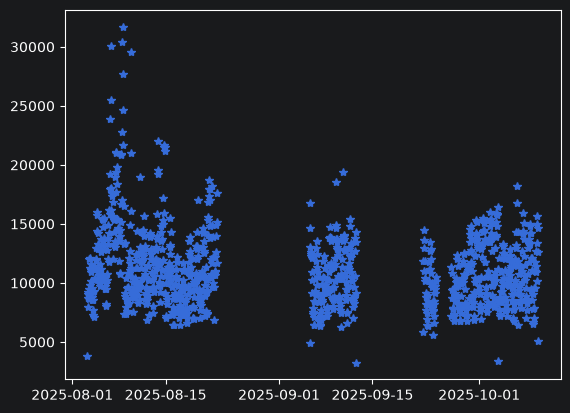

In [131]:
plt.plot(ile_transakcji_na_godzine, "*")
plt.show()

In [114]:
prog1 = np.datetime64('2025-09-01 20:44:17')
prog2 = np.datetime64('2025-09-15 20:44:17')
prog3 =  np.datetime64('2025-09-26 02:44:17')

In [123]:
okres1 = ile_transakcji_na_godzine[
    ile_transakcji_na_godzine.index < prog1
]

okres2 = ile_transakcji_na_godzine[
    (ile_transakcji_na_godzine.index >= prog1) &
    (ile_transakcji_na_godzine.index < prog2)
]

okres3 = ile_transakcji_na_godzine[
    (ile_transakcji_na_godzine.index >= prog2) &
    (ile_transakcji_na_godzine.index < prog3)
]

okres4 = ile_transakcji_na_godzine[
    ile_transakcji_na_godzine.index >= prog3
]

In [ ]:
plt.plt()

### Okres 1

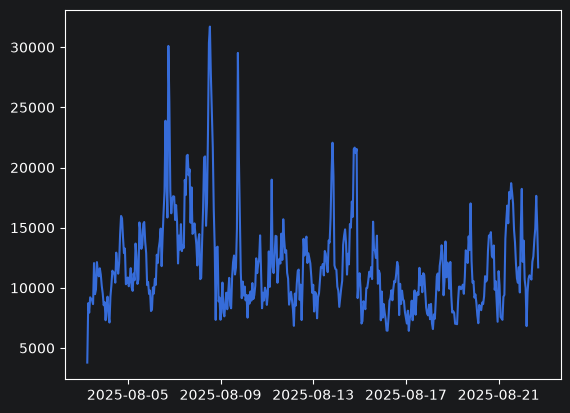

In [125]:
plt.plot(okres1)
plt.show()

### Okres 2

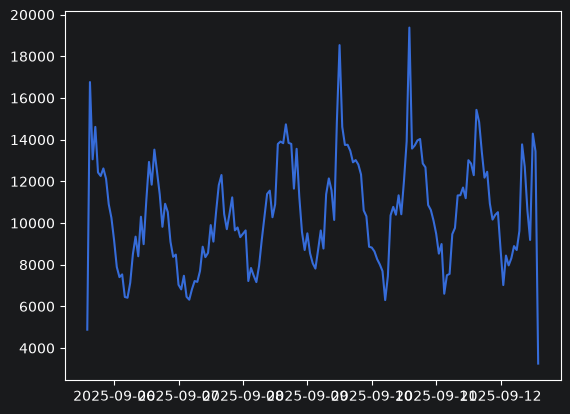

In [127]:
plt.plot(okres2)
plt.show()

### Okres 3

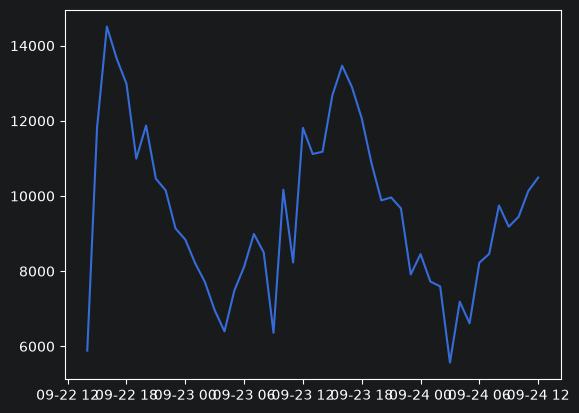

In [128]:
plt.plot(okres3)
plt.show()

### Okres 4

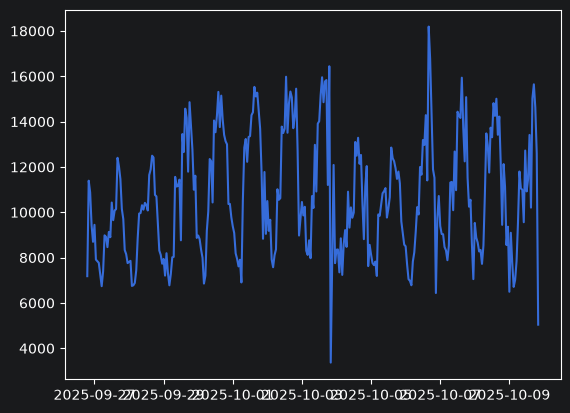

In [130]:
plt.plot(okres4)
plt.show()

# Wykresy dzien po dniu

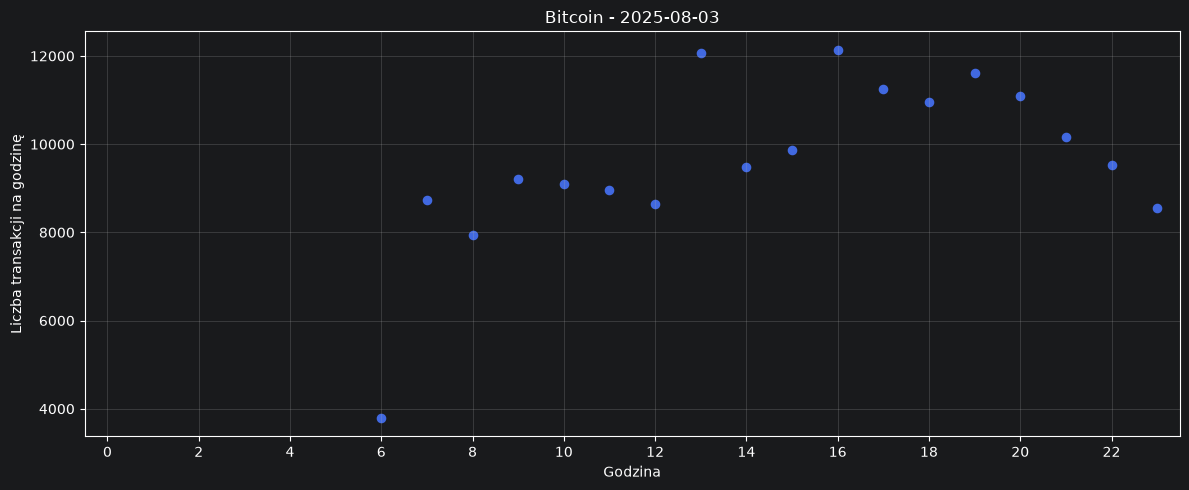

2025-08-03 - liczba obserwowanych godzin: 18


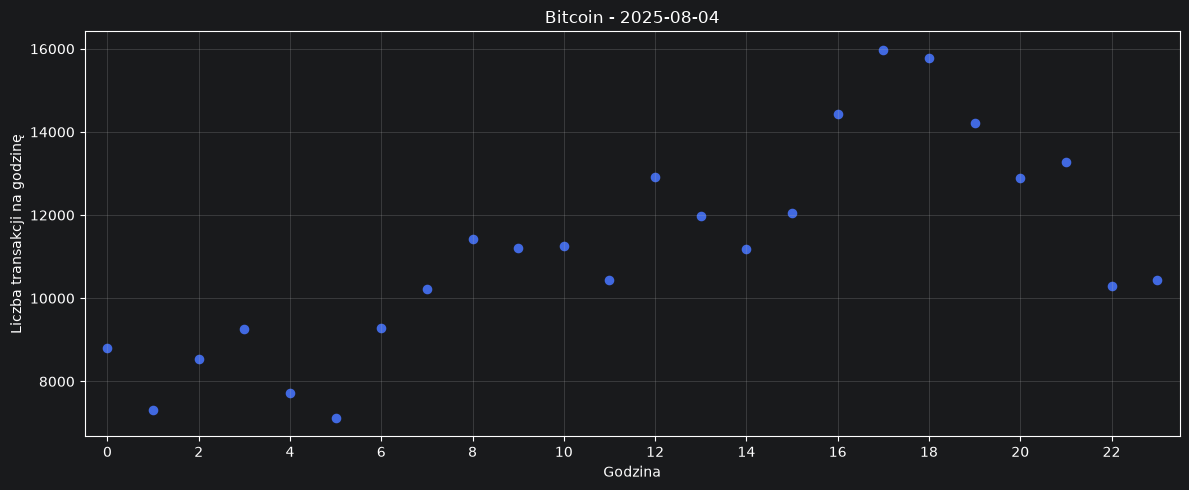

2025-08-04 - liczba obserwowanych godzin: 24


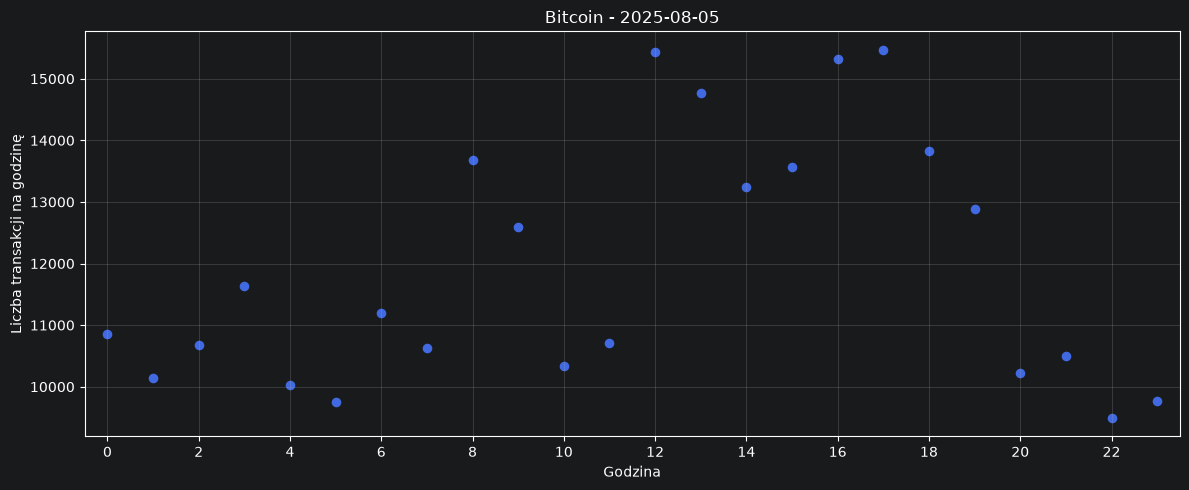

2025-08-05 - liczba obserwowanych godzin: 24


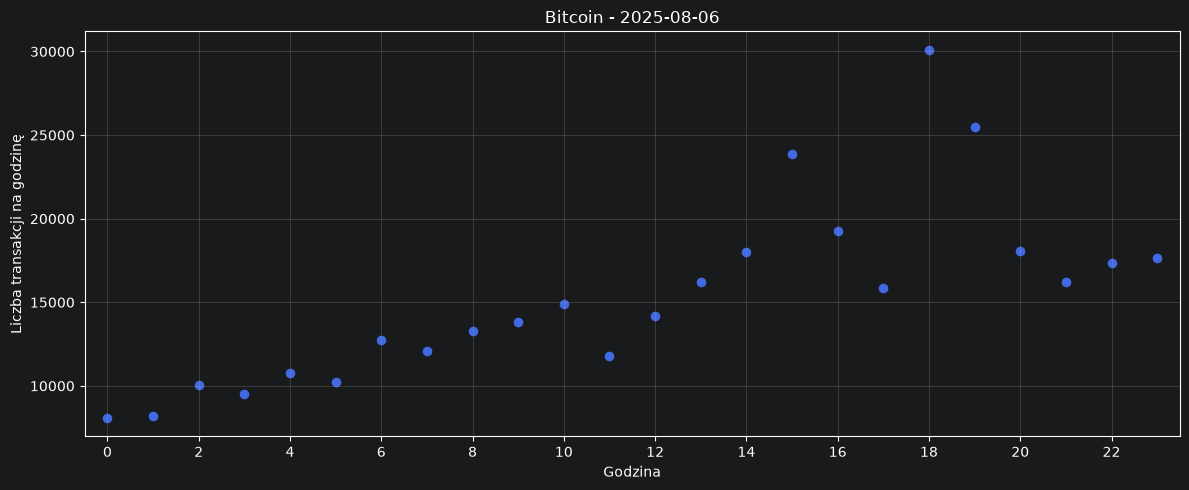

2025-08-06 - liczba obserwowanych godzin: 24


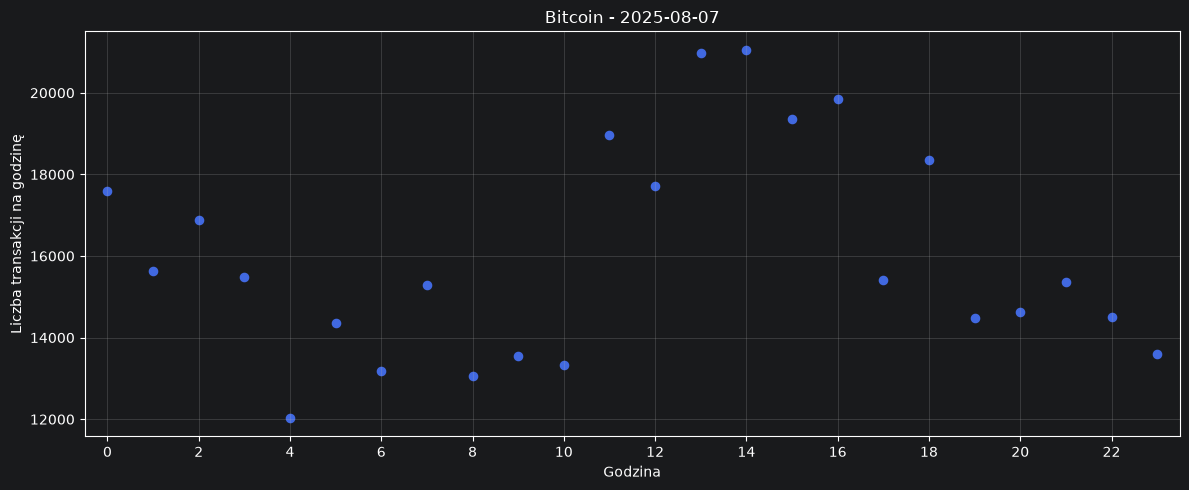

2025-08-07 - liczba obserwowanych godzin: 24


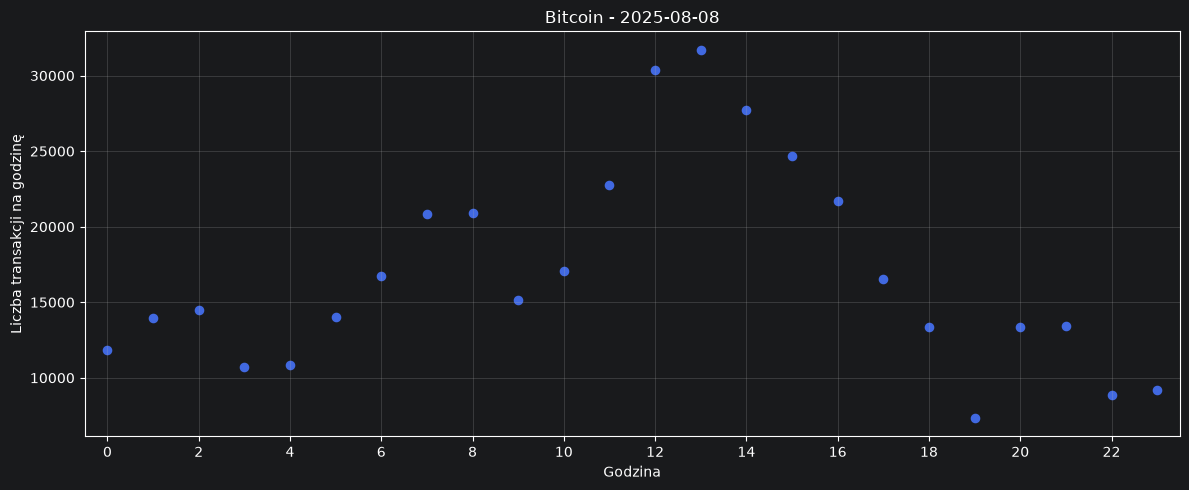

2025-08-08 - liczba obserwowanych godzin: 24


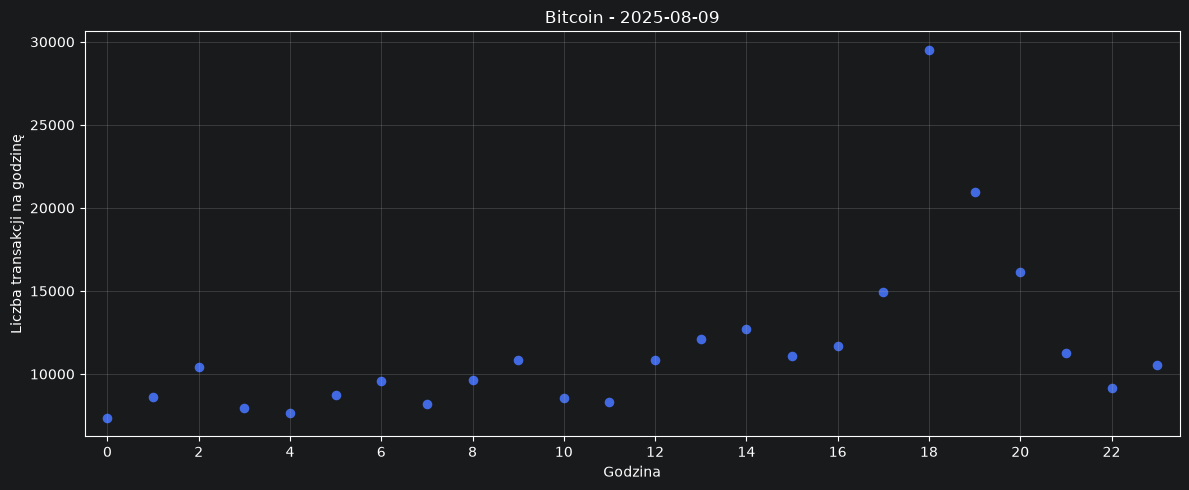

2025-08-09 - liczba obserwowanych godzin: 24


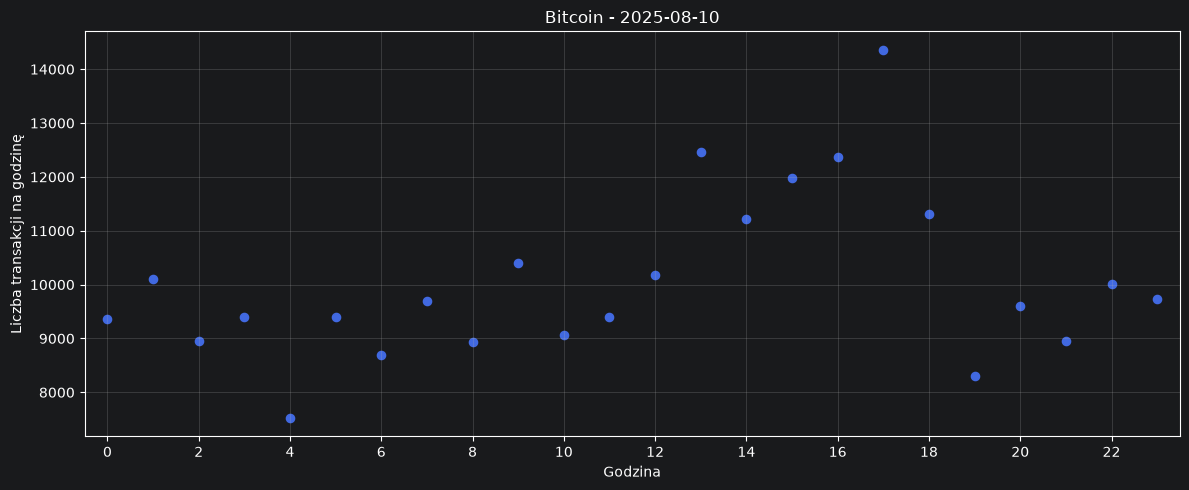

2025-08-10 - liczba obserwowanych godzin: 24


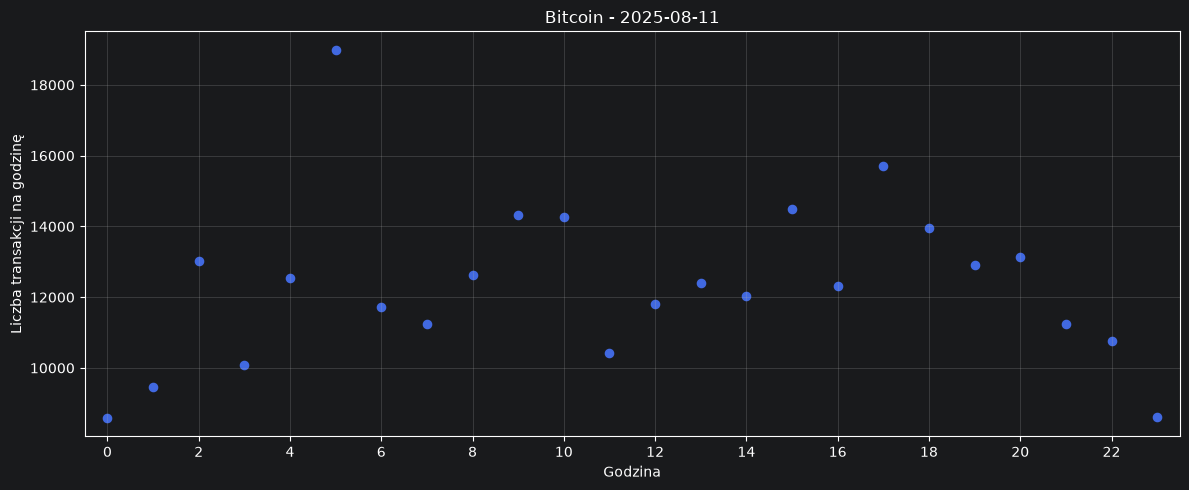

2025-08-11 - liczba obserwowanych godzin: 24


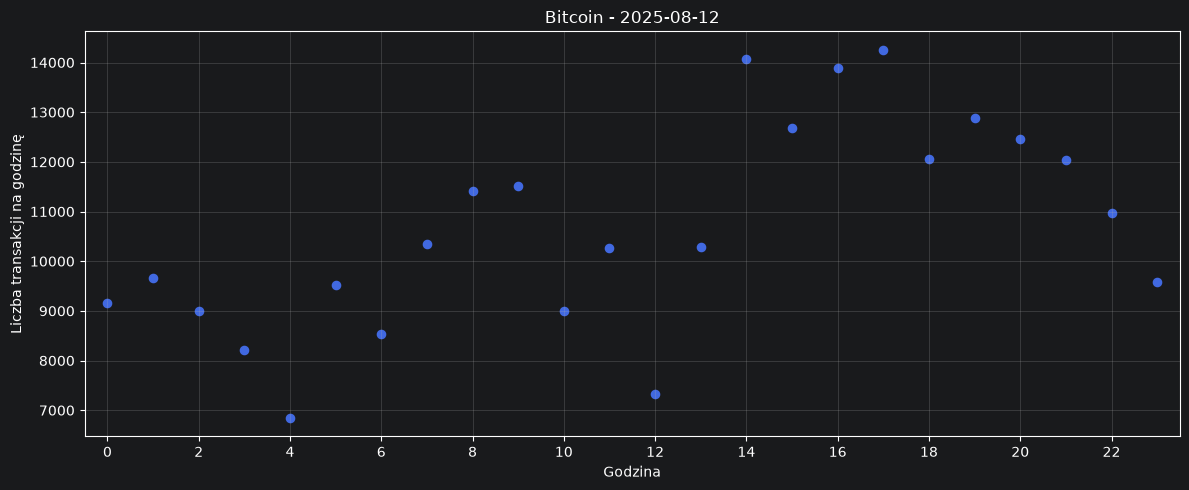

2025-08-12 - liczba obserwowanych godzin: 24


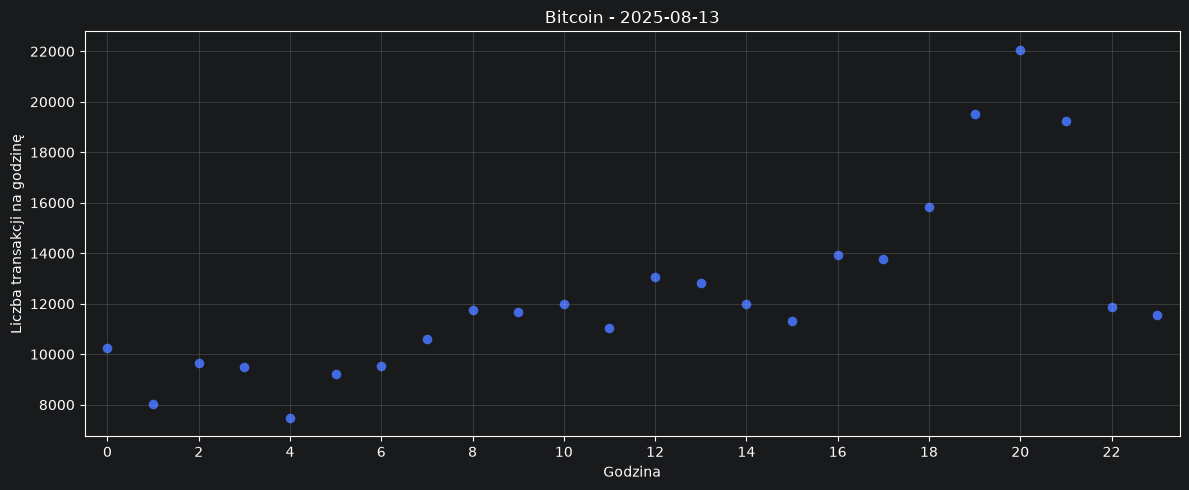

2025-08-13 - liczba obserwowanych godzin: 24


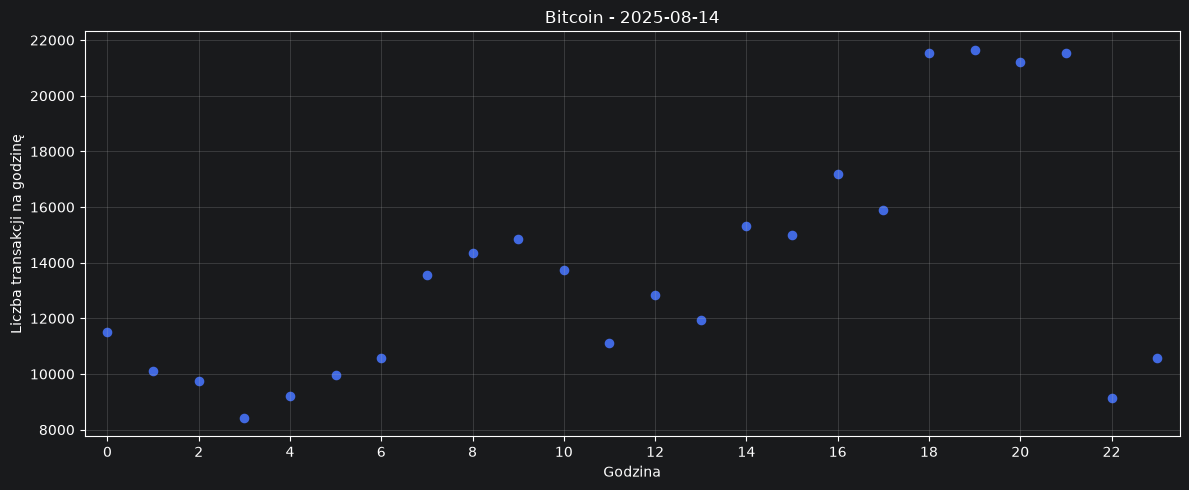

2025-08-14 - liczba obserwowanych godzin: 24


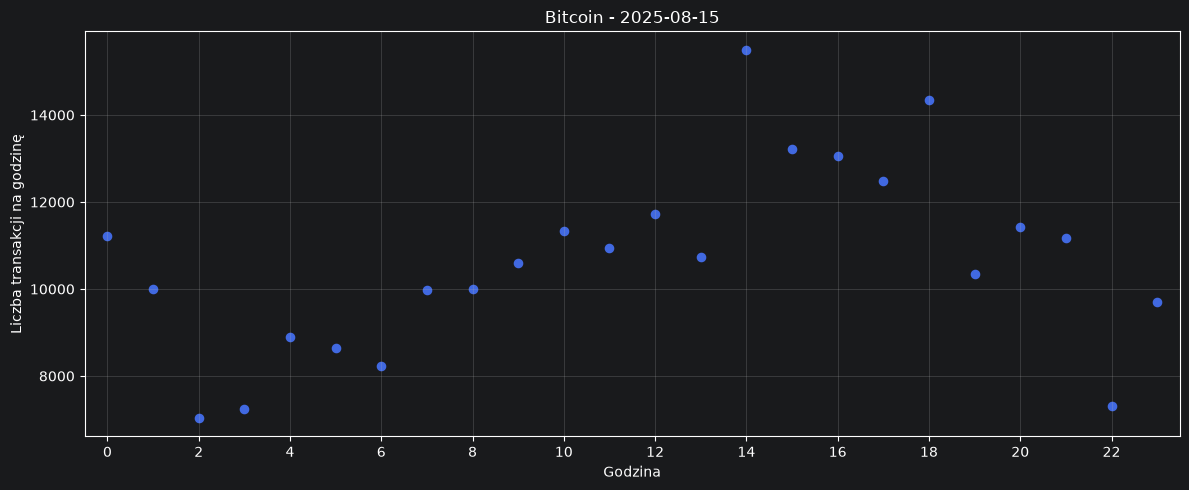

2025-08-15 - liczba obserwowanych godzin: 24


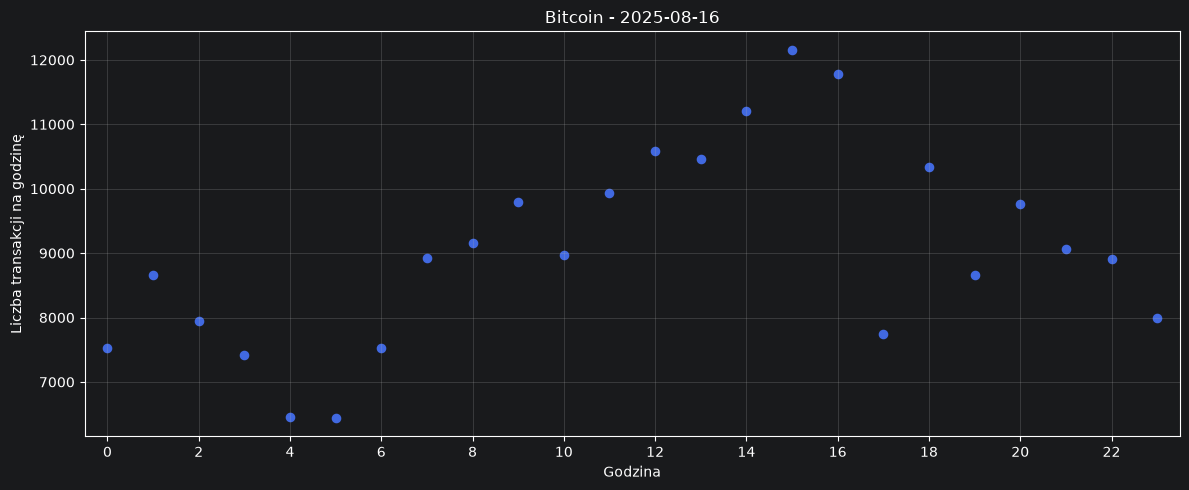

2025-08-16 - liczba obserwowanych godzin: 24


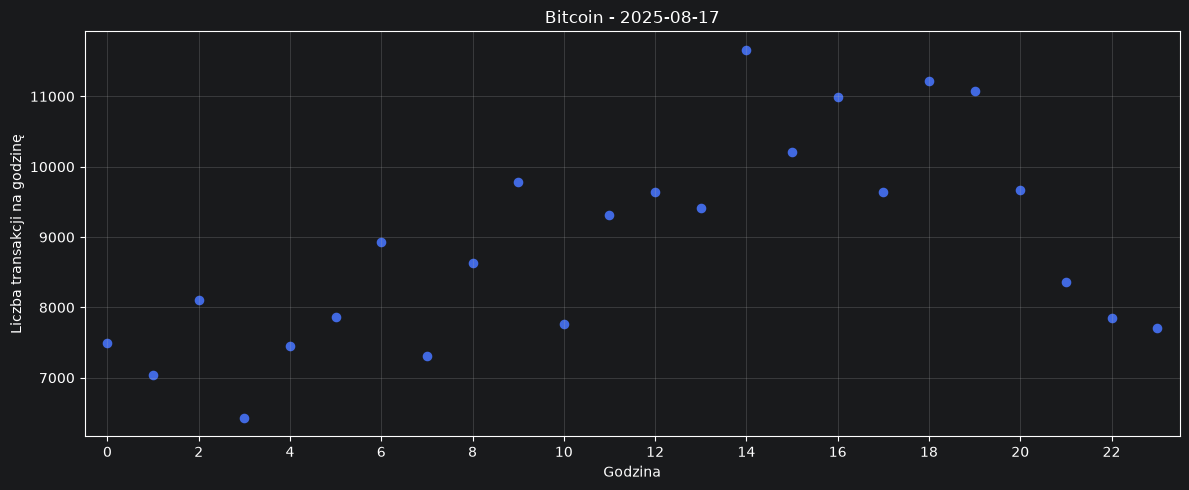

2025-08-17 - liczba obserwowanych godzin: 24


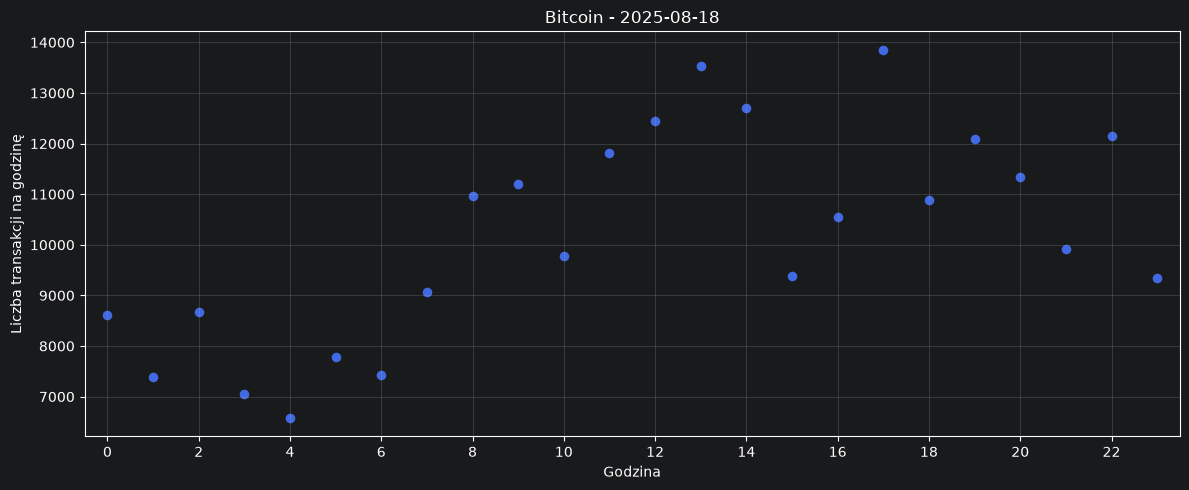

2025-08-18 - liczba obserwowanych godzin: 24


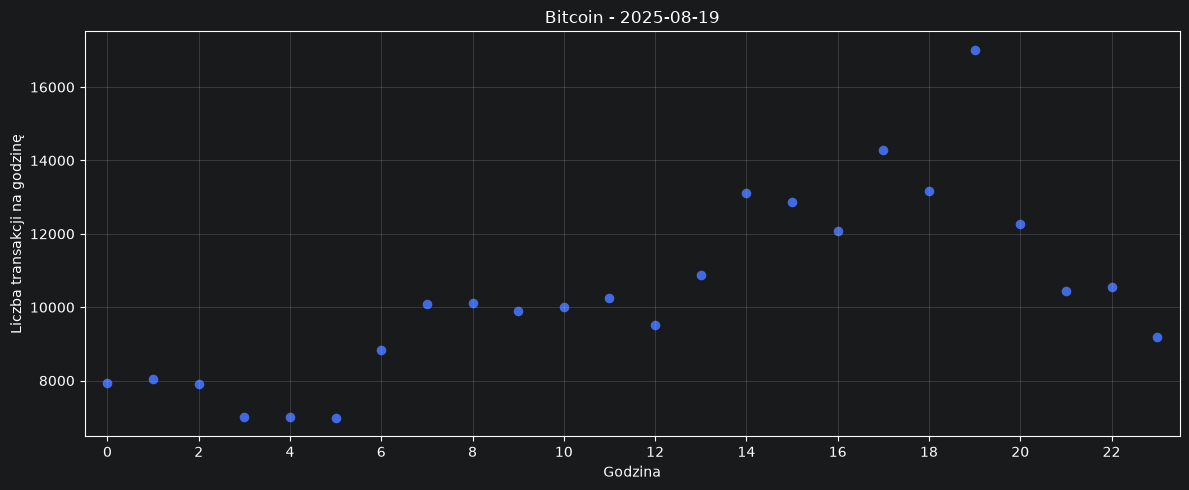

2025-08-19 - liczba obserwowanych godzin: 24


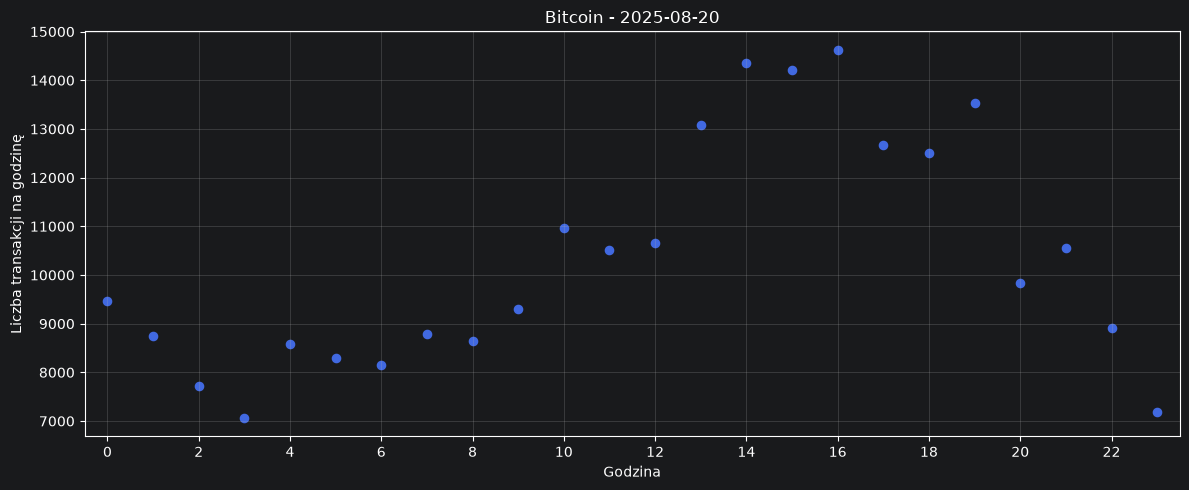

2025-08-20 - liczba obserwowanych godzin: 24


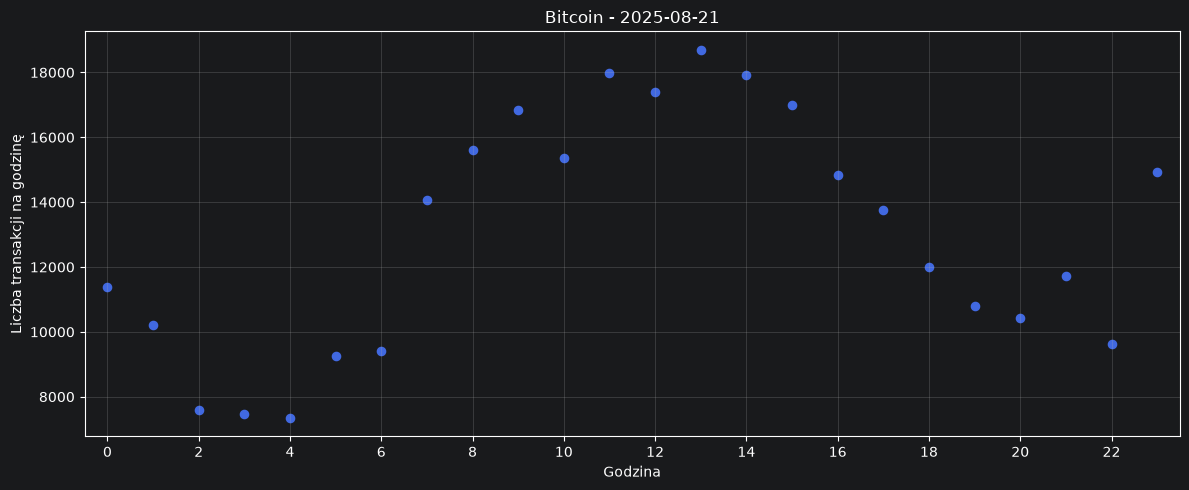

2025-08-21 - liczba obserwowanych godzin: 24


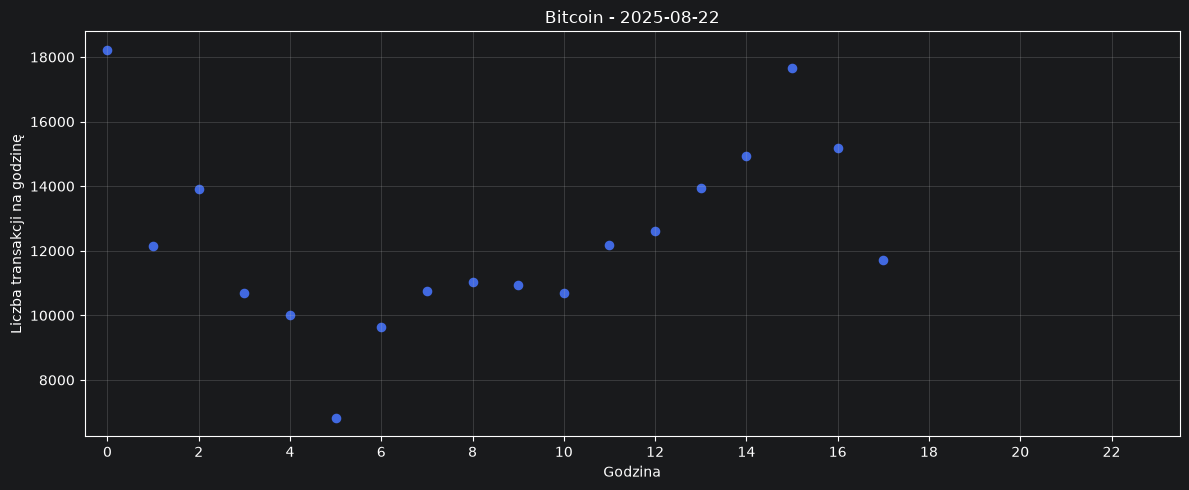

2025-08-22 - liczba obserwowanych godzin: 18


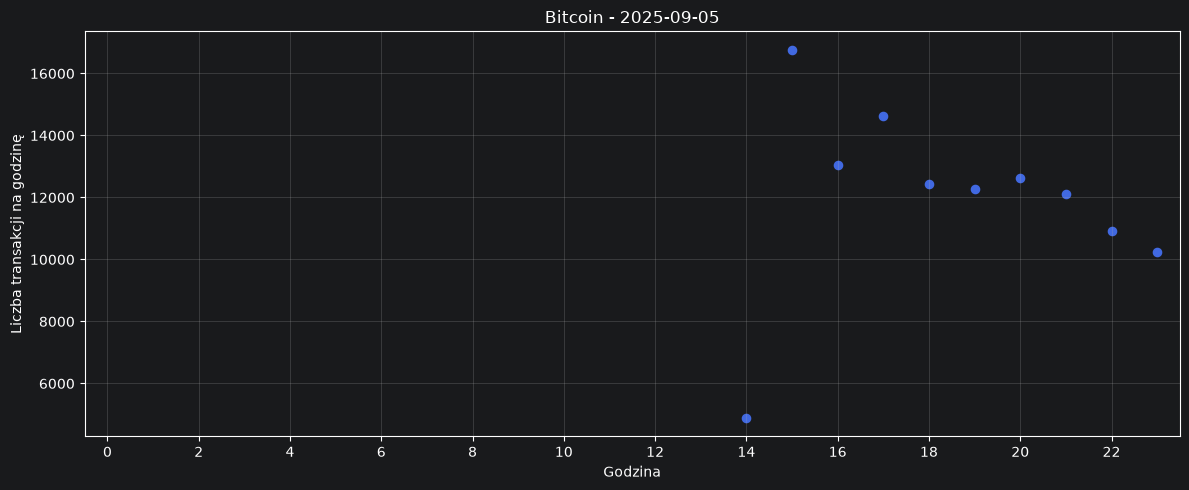

2025-09-05 - liczba obserwowanych godzin: 10


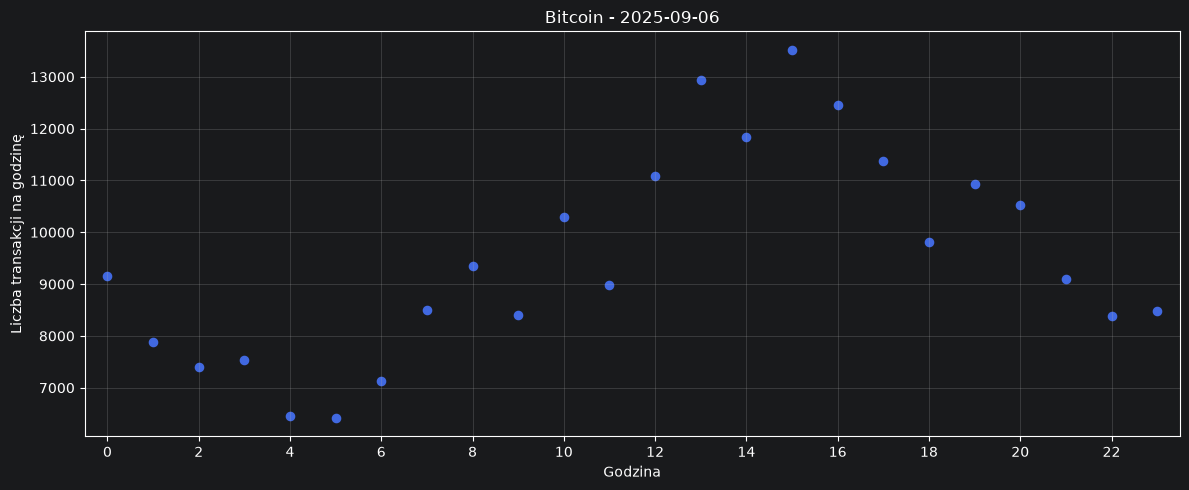

2025-09-06 - liczba obserwowanych godzin: 24


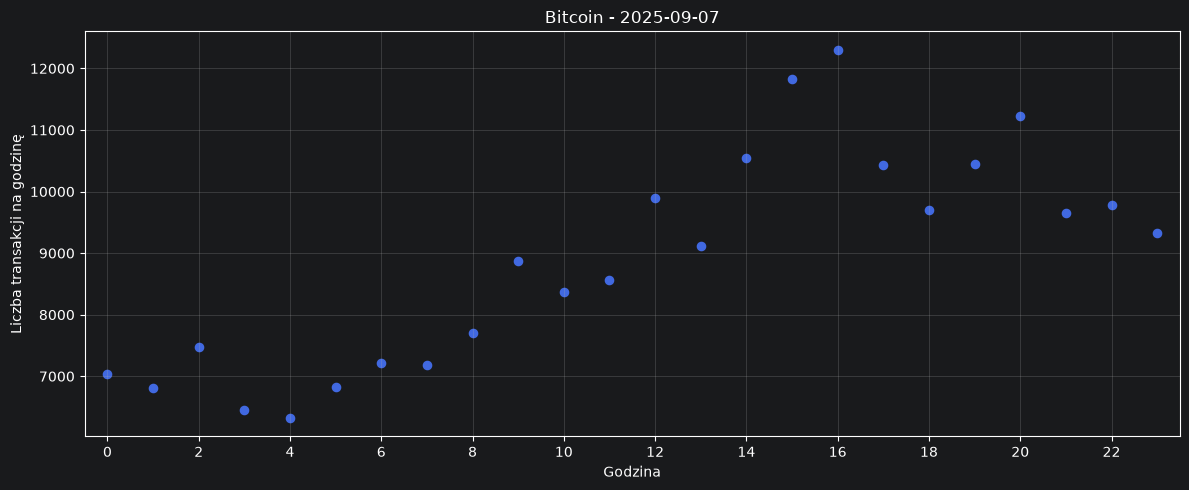

2025-09-07 - liczba obserwowanych godzin: 24


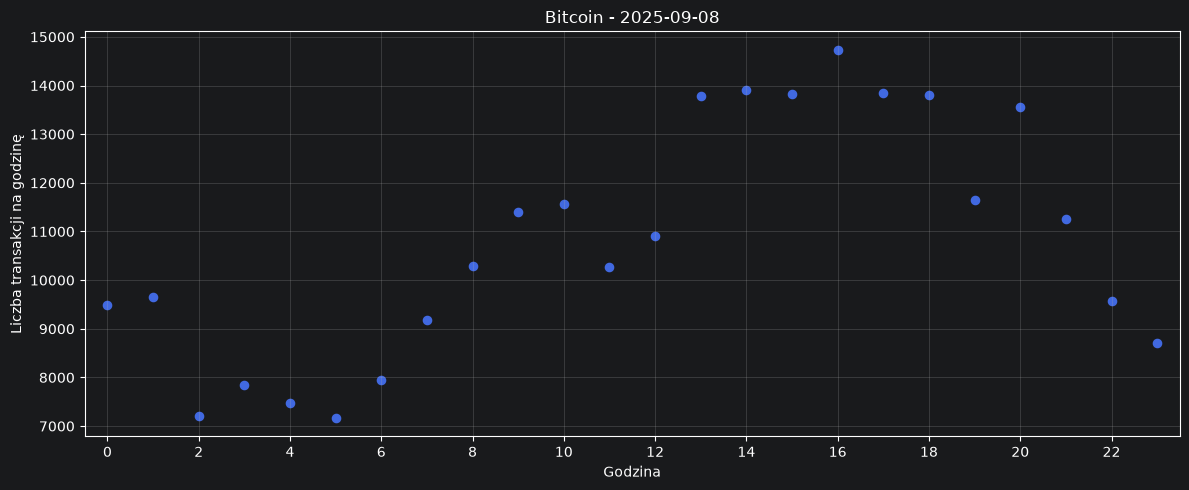

2025-09-08 - liczba obserwowanych godzin: 24


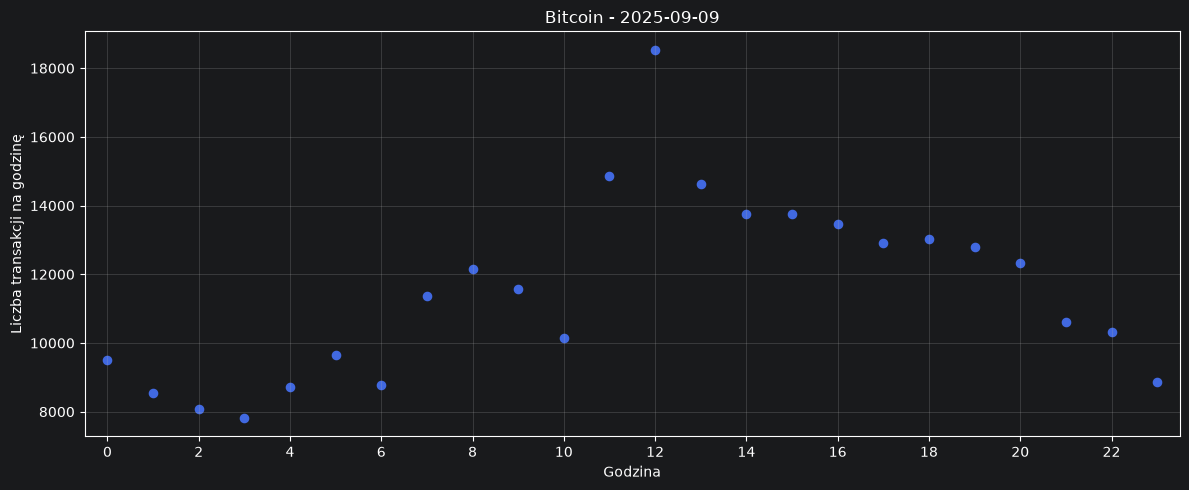

2025-09-09 - liczba obserwowanych godzin: 24


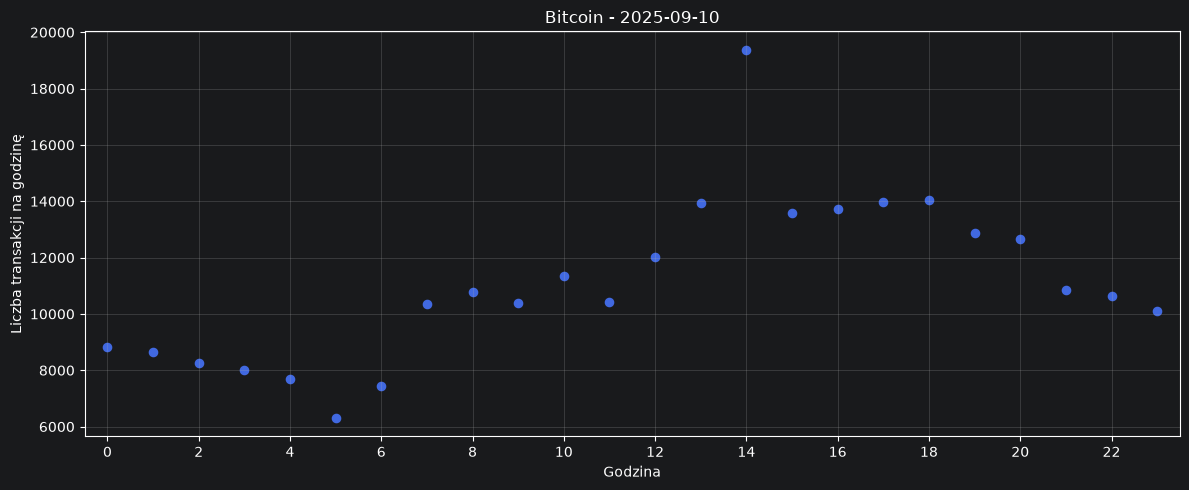

2025-09-10 - liczba obserwowanych godzin: 24


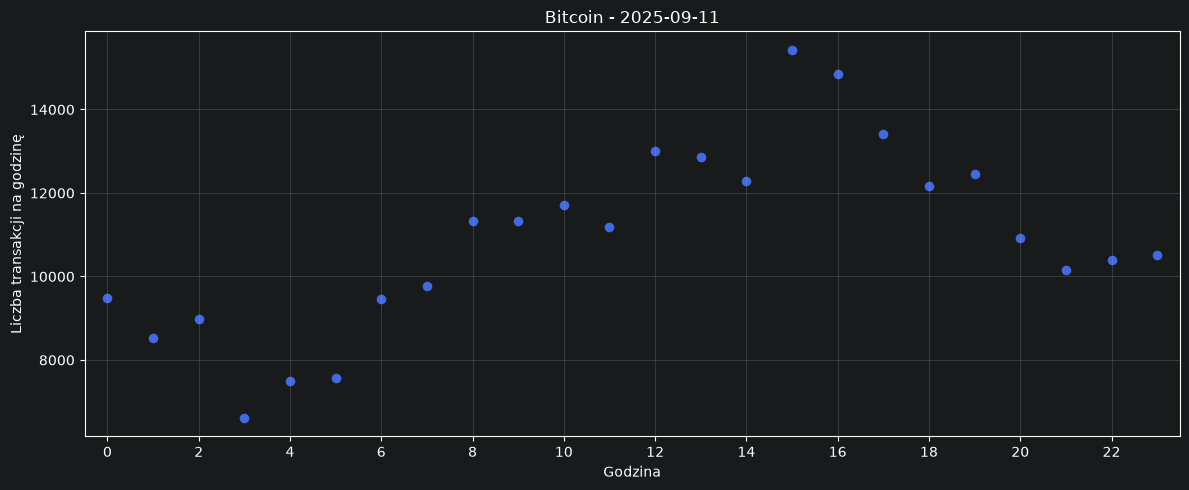

2025-09-11 - liczba obserwowanych godzin: 24


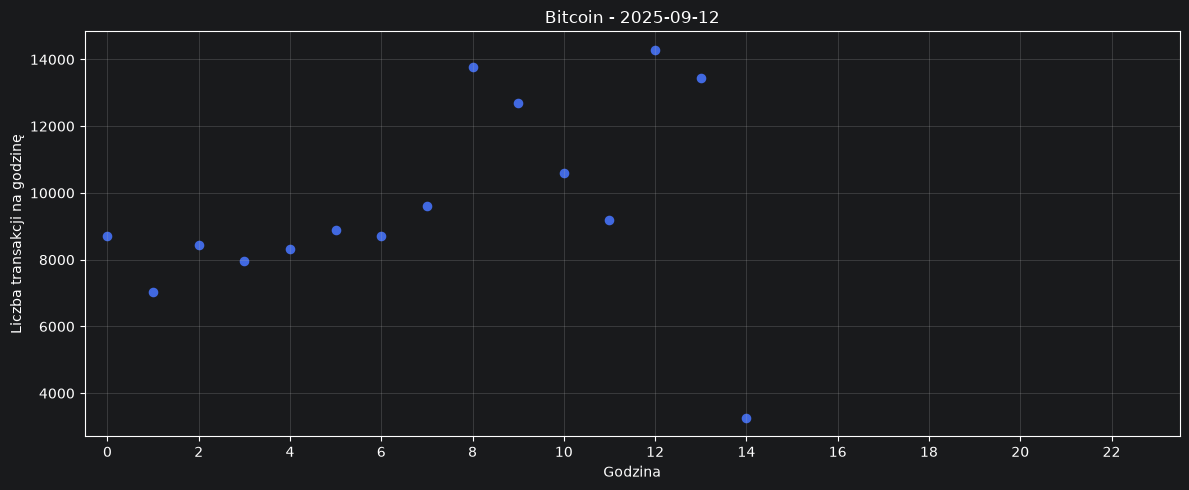

2025-09-12 - liczba obserwowanych godzin: 15


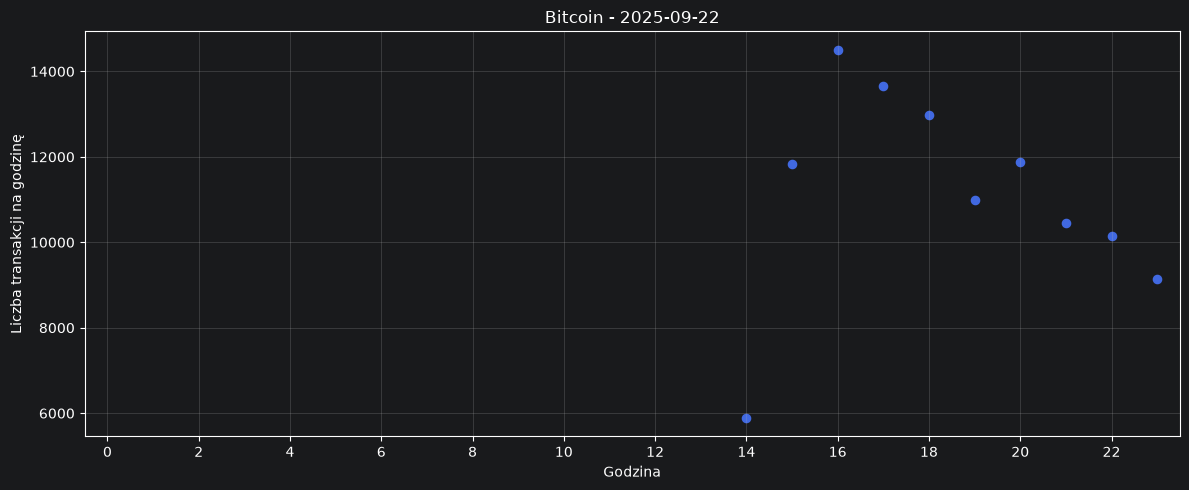

2025-09-22 - liczba obserwowanych godzin: 10


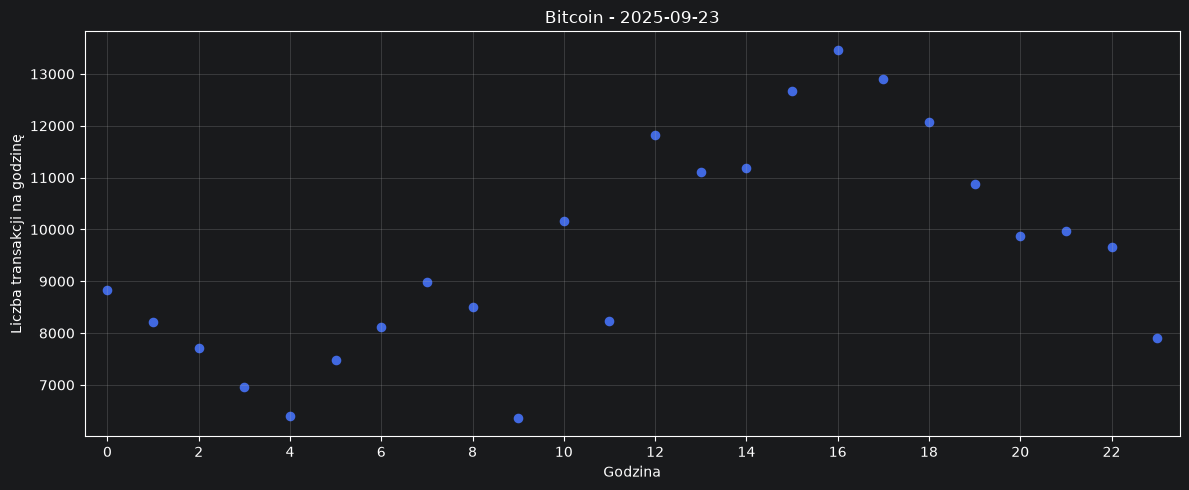

2025-09-23 - liczba obserwowanych godzin: 24


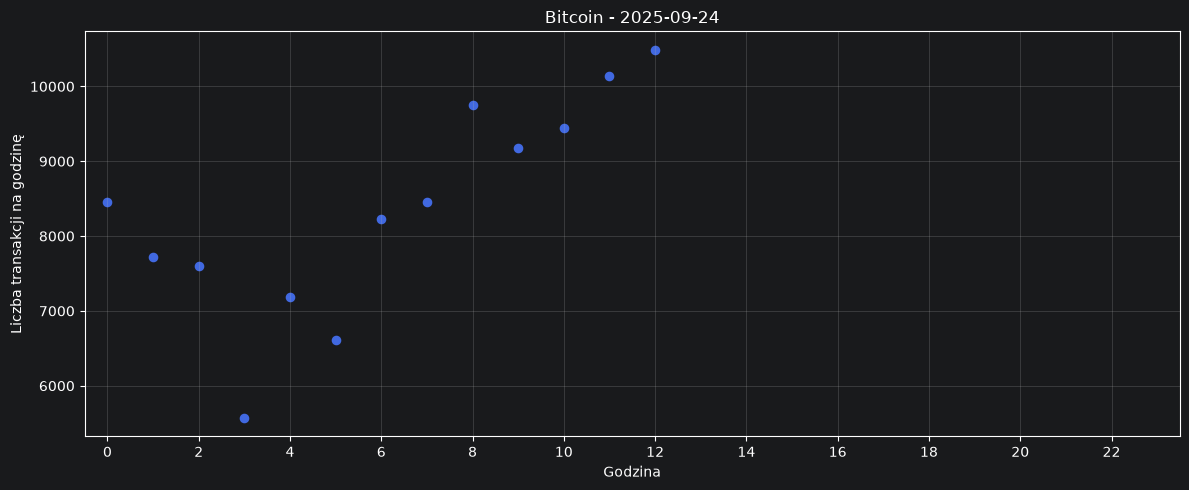

2025-09-24 - liczba obserwowanych godzin: 13


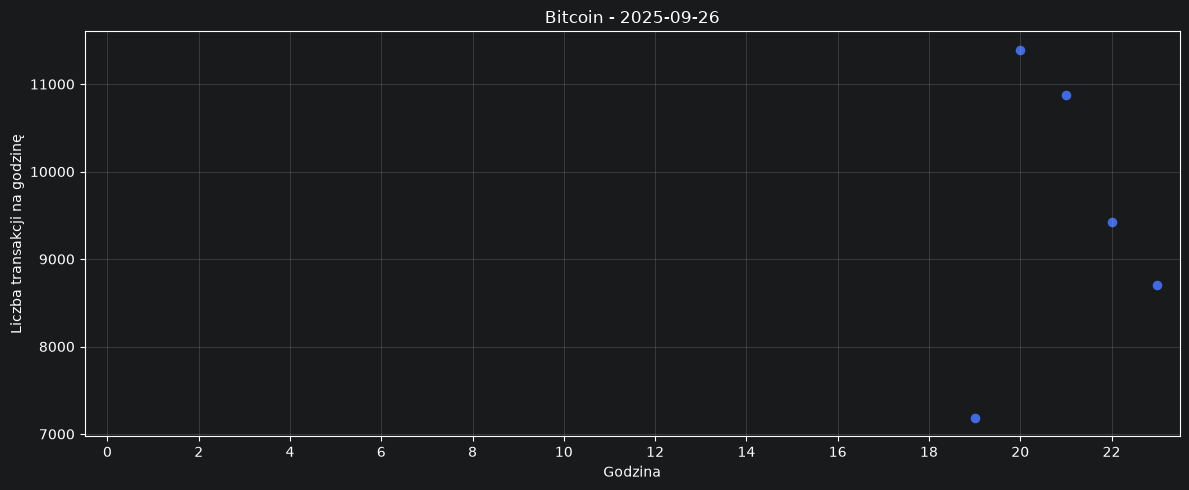

2025-09-26 - liczba obserwowanych godzin: 5


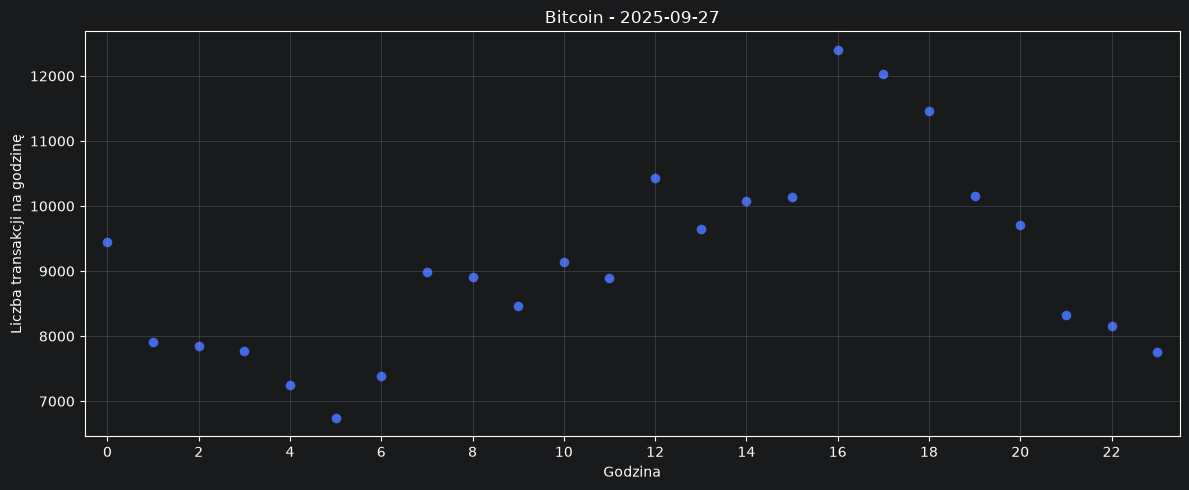

2025-09-27 - liczba obserwowanych godzin: 24


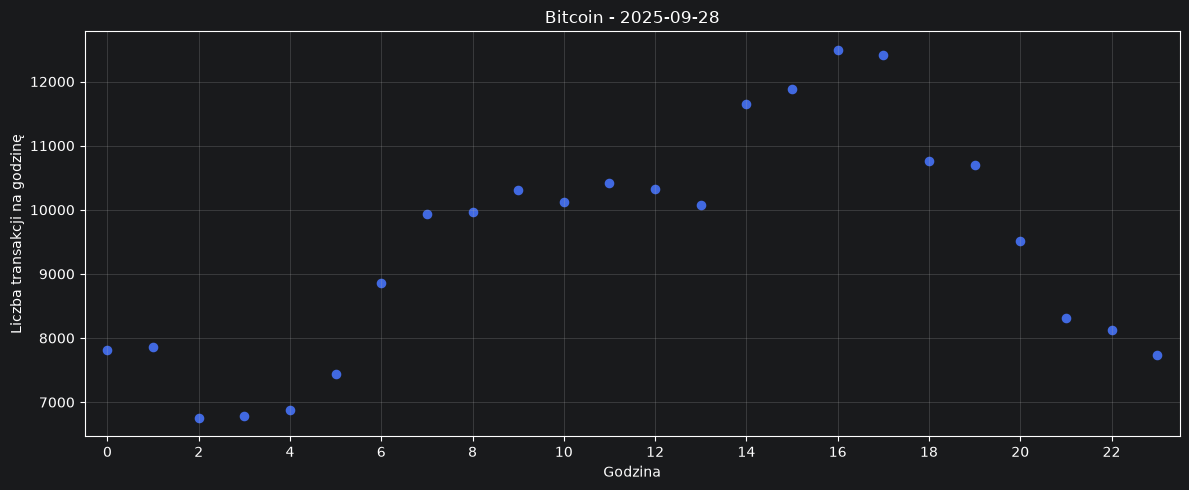

2025-09-28 - liczba obserwowanych godzin: 24


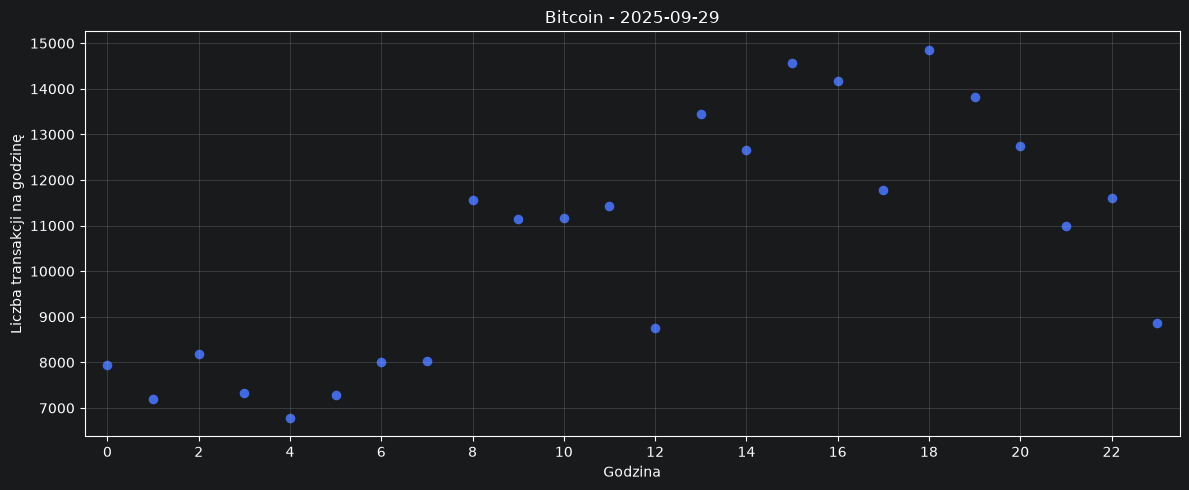

2025-09-29 - liczba obserwowanych godzin: 24


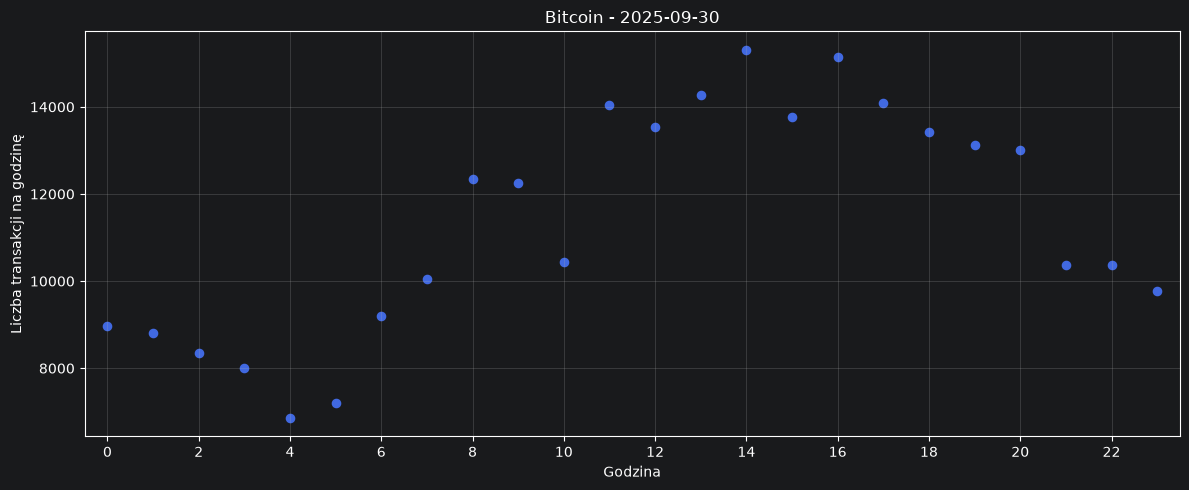

2025-09-30 - liczba obserwowanych godzin: 24


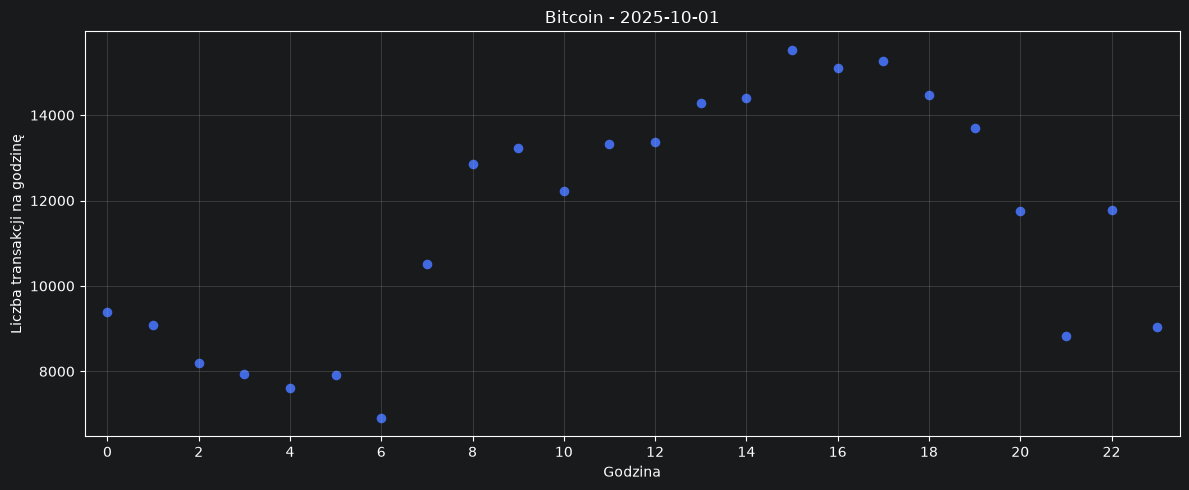

2025-10-01 - liczba obserwowanych godzin: 24


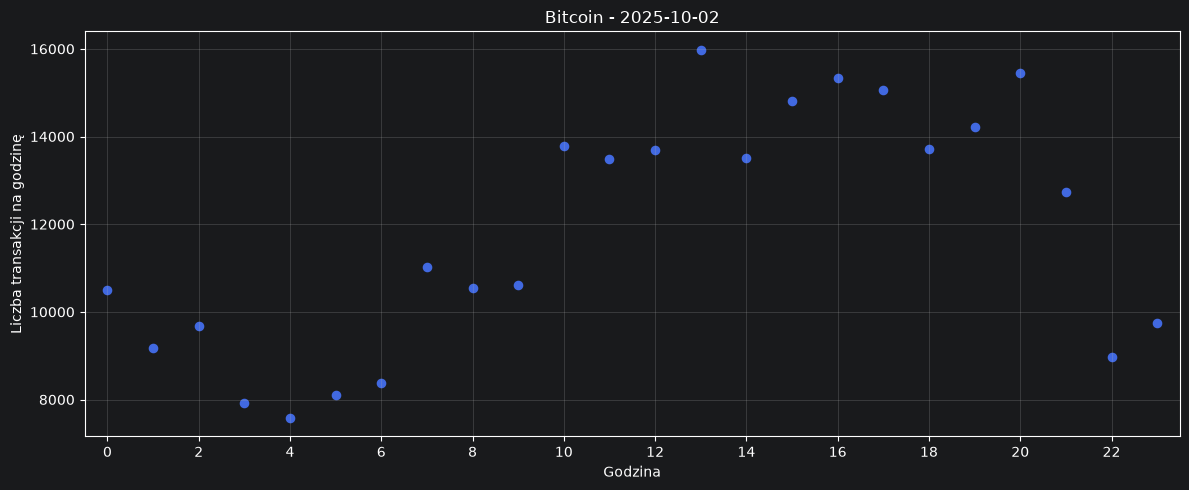

2025-10-02 - liczba obserwowanych godzin: 24


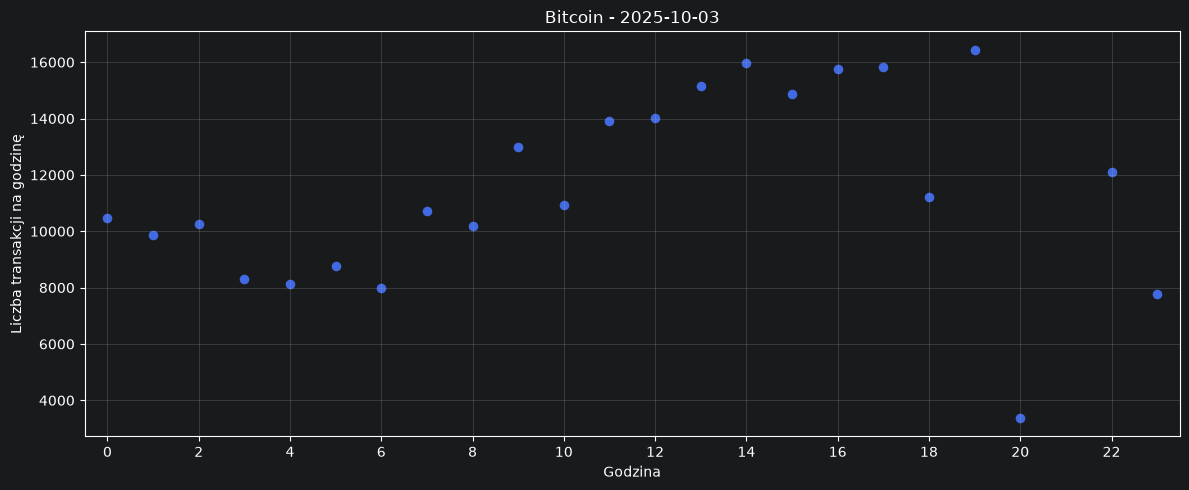

2025-10-03 - liczba obserwowanych godzin: 23


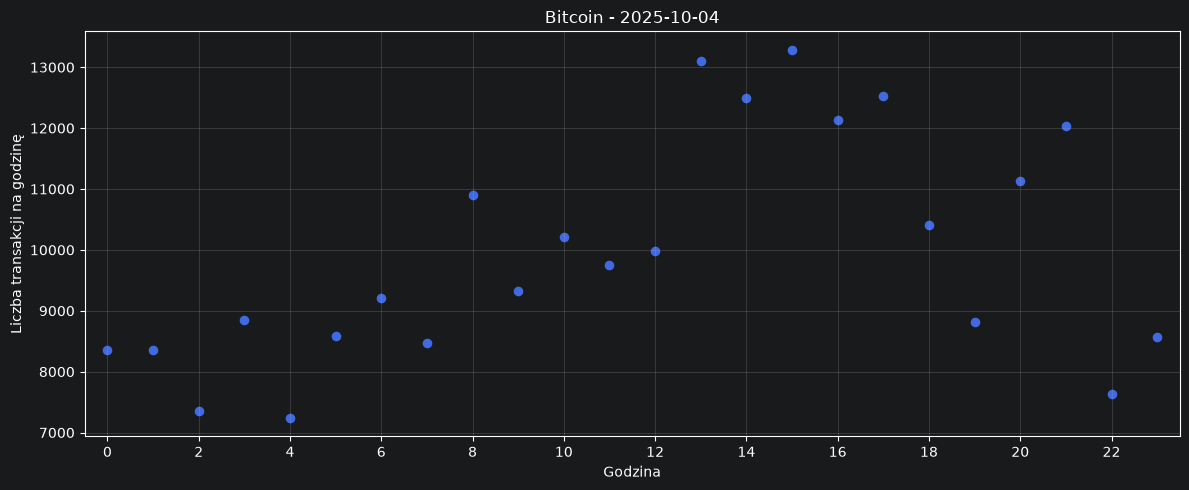

2025-10-04 - liczba obserwowanych godzin: 24


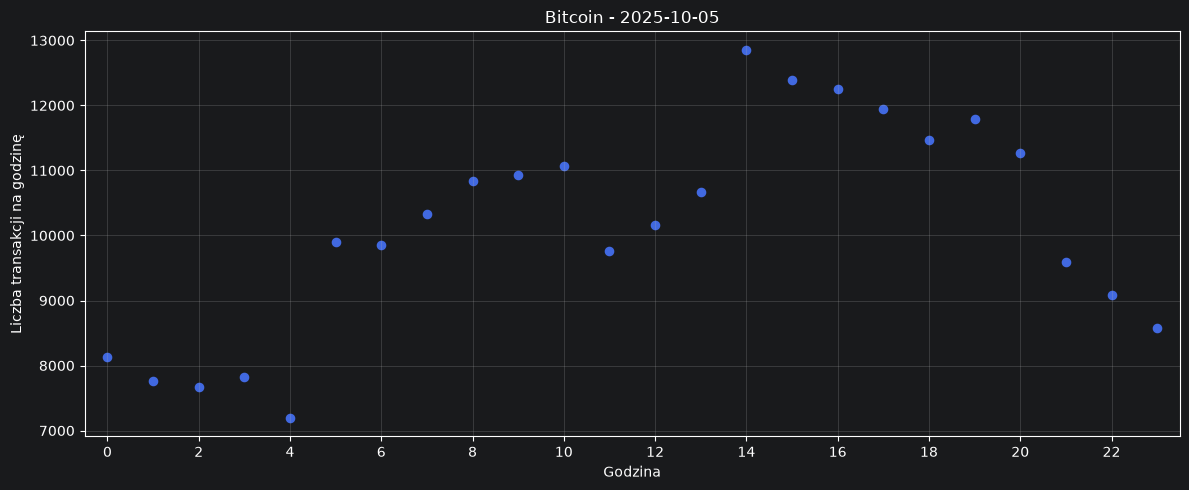

2025-10-05 - liczba obserwowanych godzin: 24


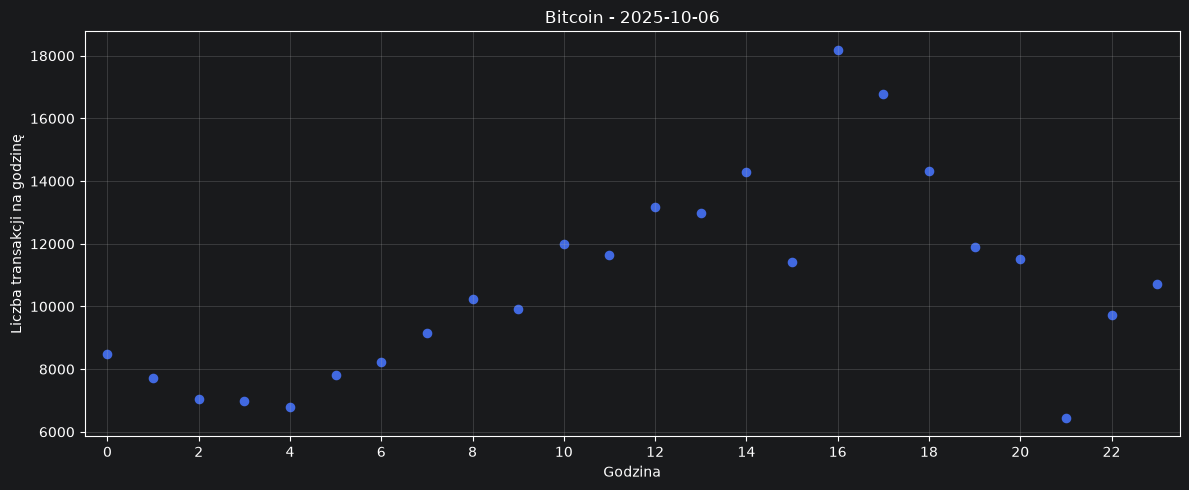

2025-10-06 - liczba obserwowanych godzin: 24


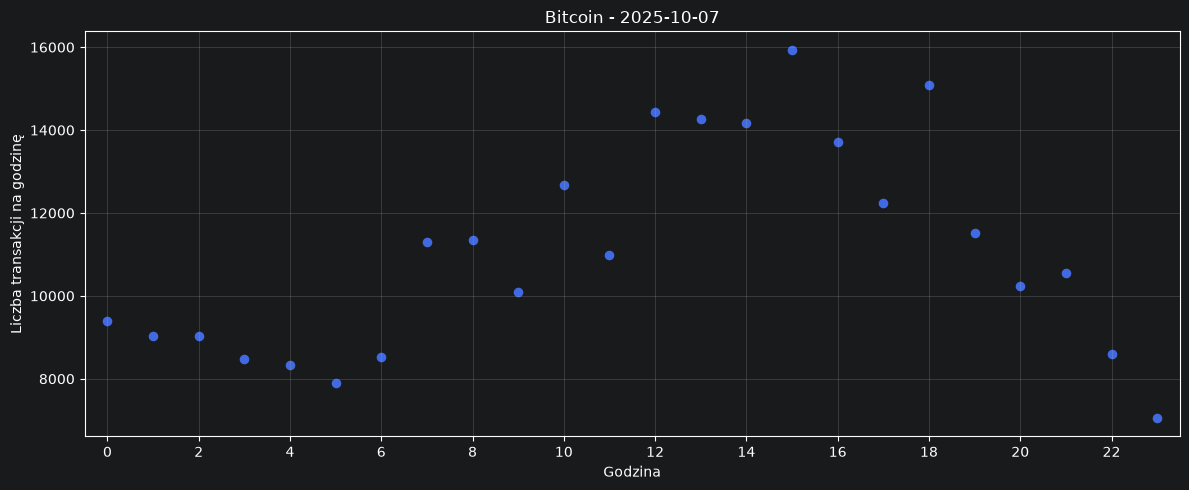

2025-10-07 - liczba obserwowanych godzin: 24


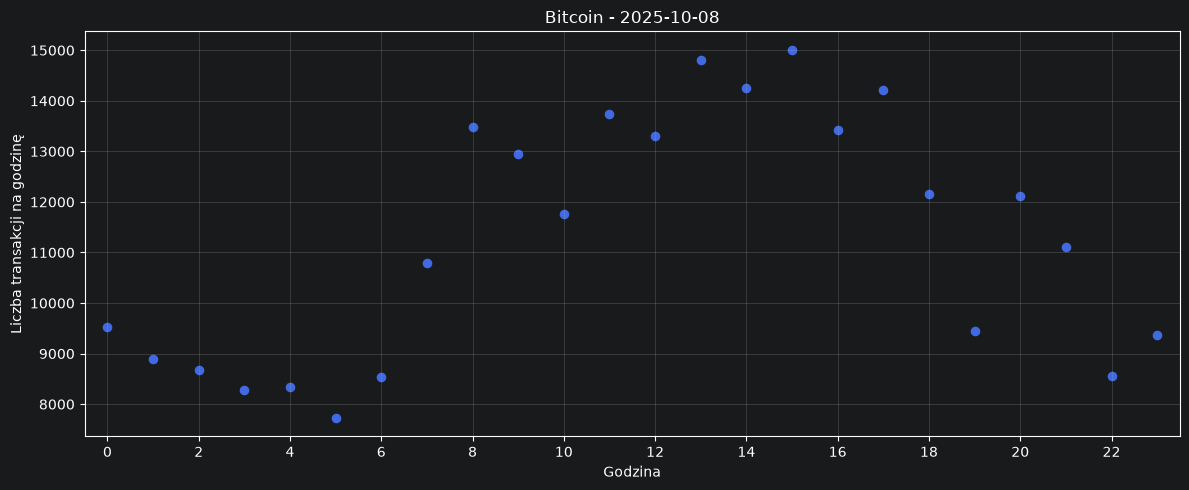

2025-10-08 - liczba obserwowanych godzin: 24


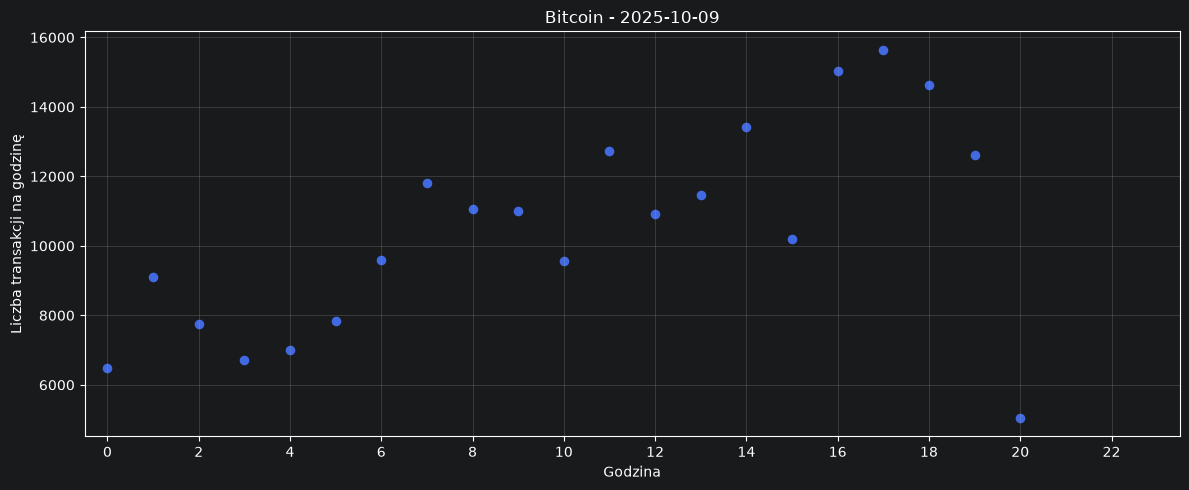

2025-10-09 - liczba obserwowanych godzin: 21


In [132]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Twoje gotowe dane godzinowe
s = ile_transakcji_na_godzine.sort_index()

# Folder na wykresy
folder = Path("wykresy_dzienne")
folder.mkdir(exist_ok=True)

# Podział na dni bez zmieniania danych
for dzien, dane_dnia in s.groupby(s.index.normalize()):

    fig, ax = plt.subplots(figsize=(12, 5))

    # Tylko godziny, dla których mamy obserwacje
    ax.scatter(
        dane_dnia.index.hour,
        dane_dnia.values,
        color="royalblue",
        s=35
    )

    ax.set_title(f"Bitcoin - {dzien.date()}")
    ax.set_xlabel("Godzina")
    ax.set_ylabel("Liczba transakcji na godzinę")

    ax.set_xlim(-0.5, 23.5)
    ax.set_xticks(range(0, 24, 2))
    ax.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        folder / f"{dzien.date()}.png",
        dpi=150
    )

    plt.show()
    plt.close(fig)

    print(
        f"{dzien.date()} - "
        f"liczba obserwowanych godzin: {len(dane_dnia)}"
    )


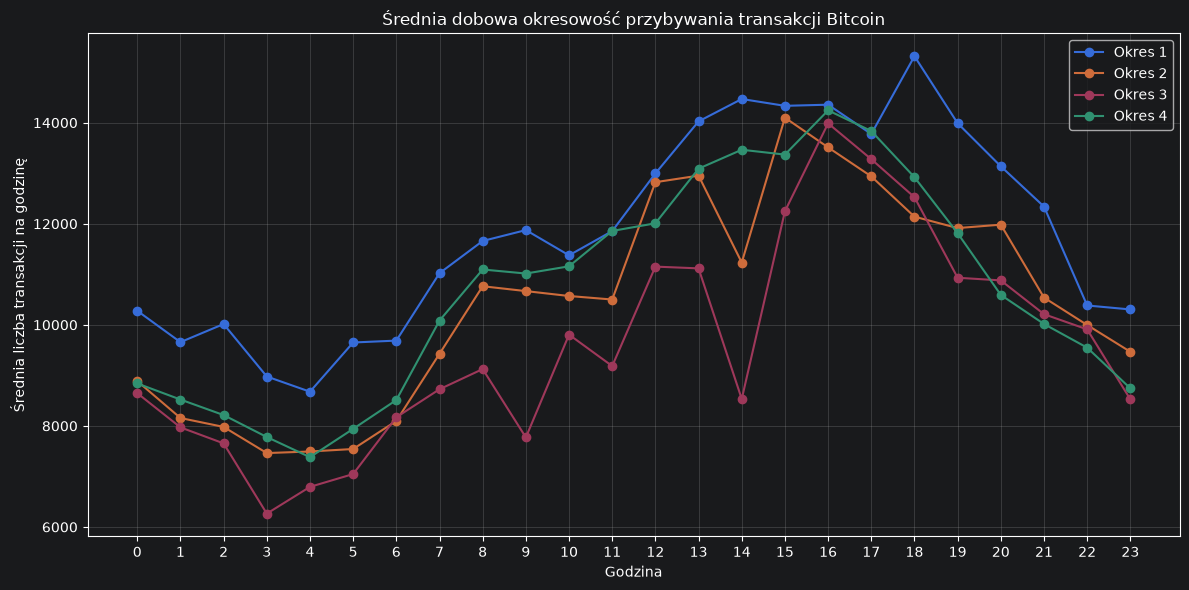

In [134]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

s = ile_transakcji_na_godzine.copy()
s.index = pd.to_datetime(s.index)
s = s.sort_index().dropna()

prog1 = pd.Timestamp('2025-09-01 20:44:17')
prog2 = pd.Timestamp('2025-09-15 20:44:17')
prog3 = pd.Timestamp('2025-09-26 02:44:17')

okresy = {
    "Okres 1": s[s.index < prog1],
    "Okres 2": s[(s.index >= prog1) & (s.index < prog2)],
    "Okres 3": s[(s.index >= prog2) & (s.index < prog3)],
    "Okres 4": s[s.index >= prog3]
}

fig, ax = plt.subplots(figsize=(12, 6))

for nazwa, dane in okresy.items():
    profil = dane.groupby(dane.index.hour).mean()
    profil = profil.reindex(range(24))

    ax.plot(
        profil.index,
        profil.values,
        marker='o',
        label=nazwa
    )

ax.set_title("Średnia dobowa okresowość przybywania transakcji Bitcoin")
ax.set_xlabel("Godzina")
ax.set_ylabel("Średnia liczba transakcji na godzinę")
ax.set_xticks(range(24))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()


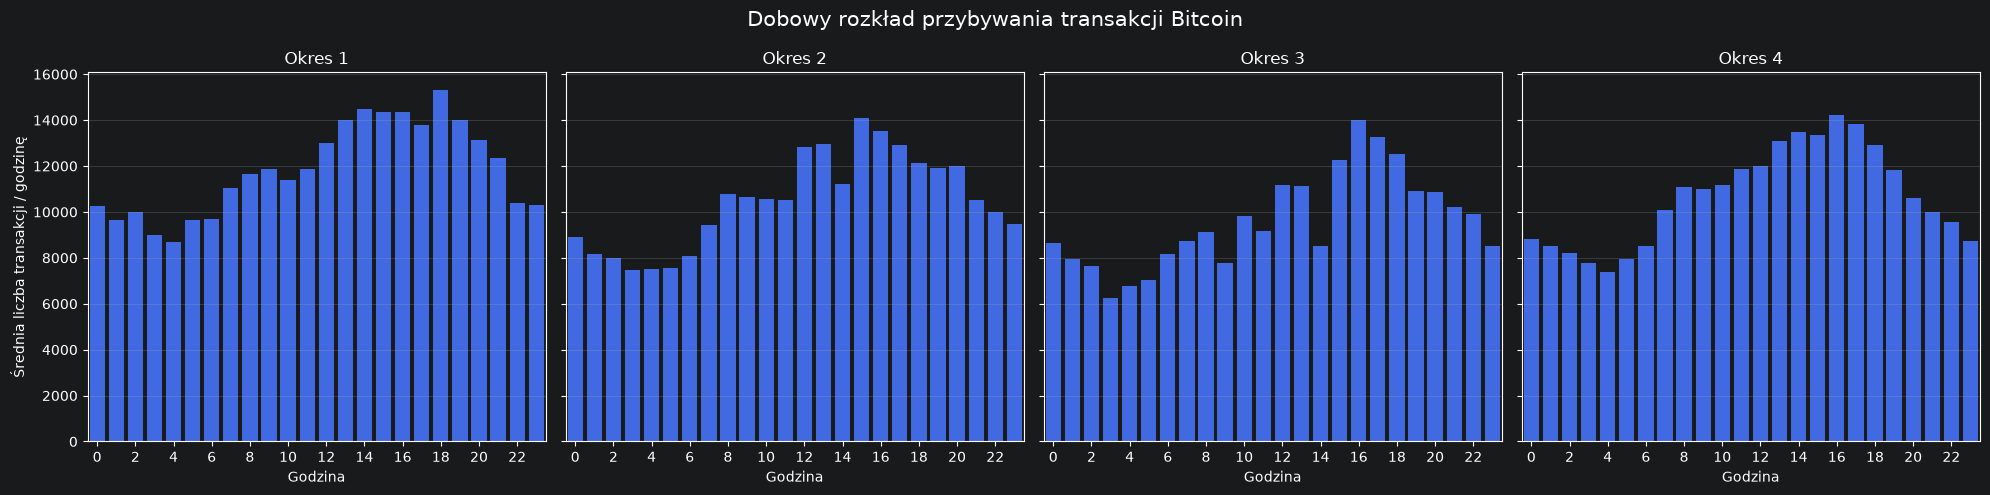

In [135]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gotowe dane godzinowe
s = ile_transakcji_na_godzine.copy()
s.index = pd.to_datetime(s.index)
s = s.sort_index().dropna()

# Progi
prog1 = pd.Timestamp('2025-09-01 20:44:17')
prog2 = pd.Timestamp('2025-09-15 20:44:17')
prog3 = pd.Timestamp('2025-09-26 02:44:17')

# Cztery okresy
okresy = {
    "Okres 1": s[s.index < prog1],
    "Okres 2": s[(s.index >= prog1) & (s.index < prog2)],
    "Okres 3": s[(s.index >= prog2) & (s.index < prog3)],
    "Okres 4": s[s.index >= prog3]
}

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
    sharey=True
)

godziny = np.arange(24)

for ax, (nazwa, dane) in zip(axes, okresy.items()):

    # Średnia liczba transakcji o danej godzinie
    profil = (
        dane.groupby(dane.index.hour)
        .mean()
        .reindex(godziny)
    )

    # Pomijamy godziny bez obserwacji
    maska = profil.notna()

    ax.bar(
        godziny[maska],
        profil[maska],
        width=0.8,
        color="royalblue"
    )

    ax.set_title(nazwa)
    ax.set_xlabel("Godzina")
    ax.set_xticks(range(0, 24, 2))
    ax.set_xlim(-0.5, 23.5)
    ax.grid(axis="y", alpha=0.3)

axes[0].set_ylabel("Średnia liczba transakcji / godzinę")

fig.suptitle(
    "Dobowy rozkład przybywania transakcji Bitcoin",
    fontsize=15
)

plt.tight_layout()
plt.show()


## Heatmap

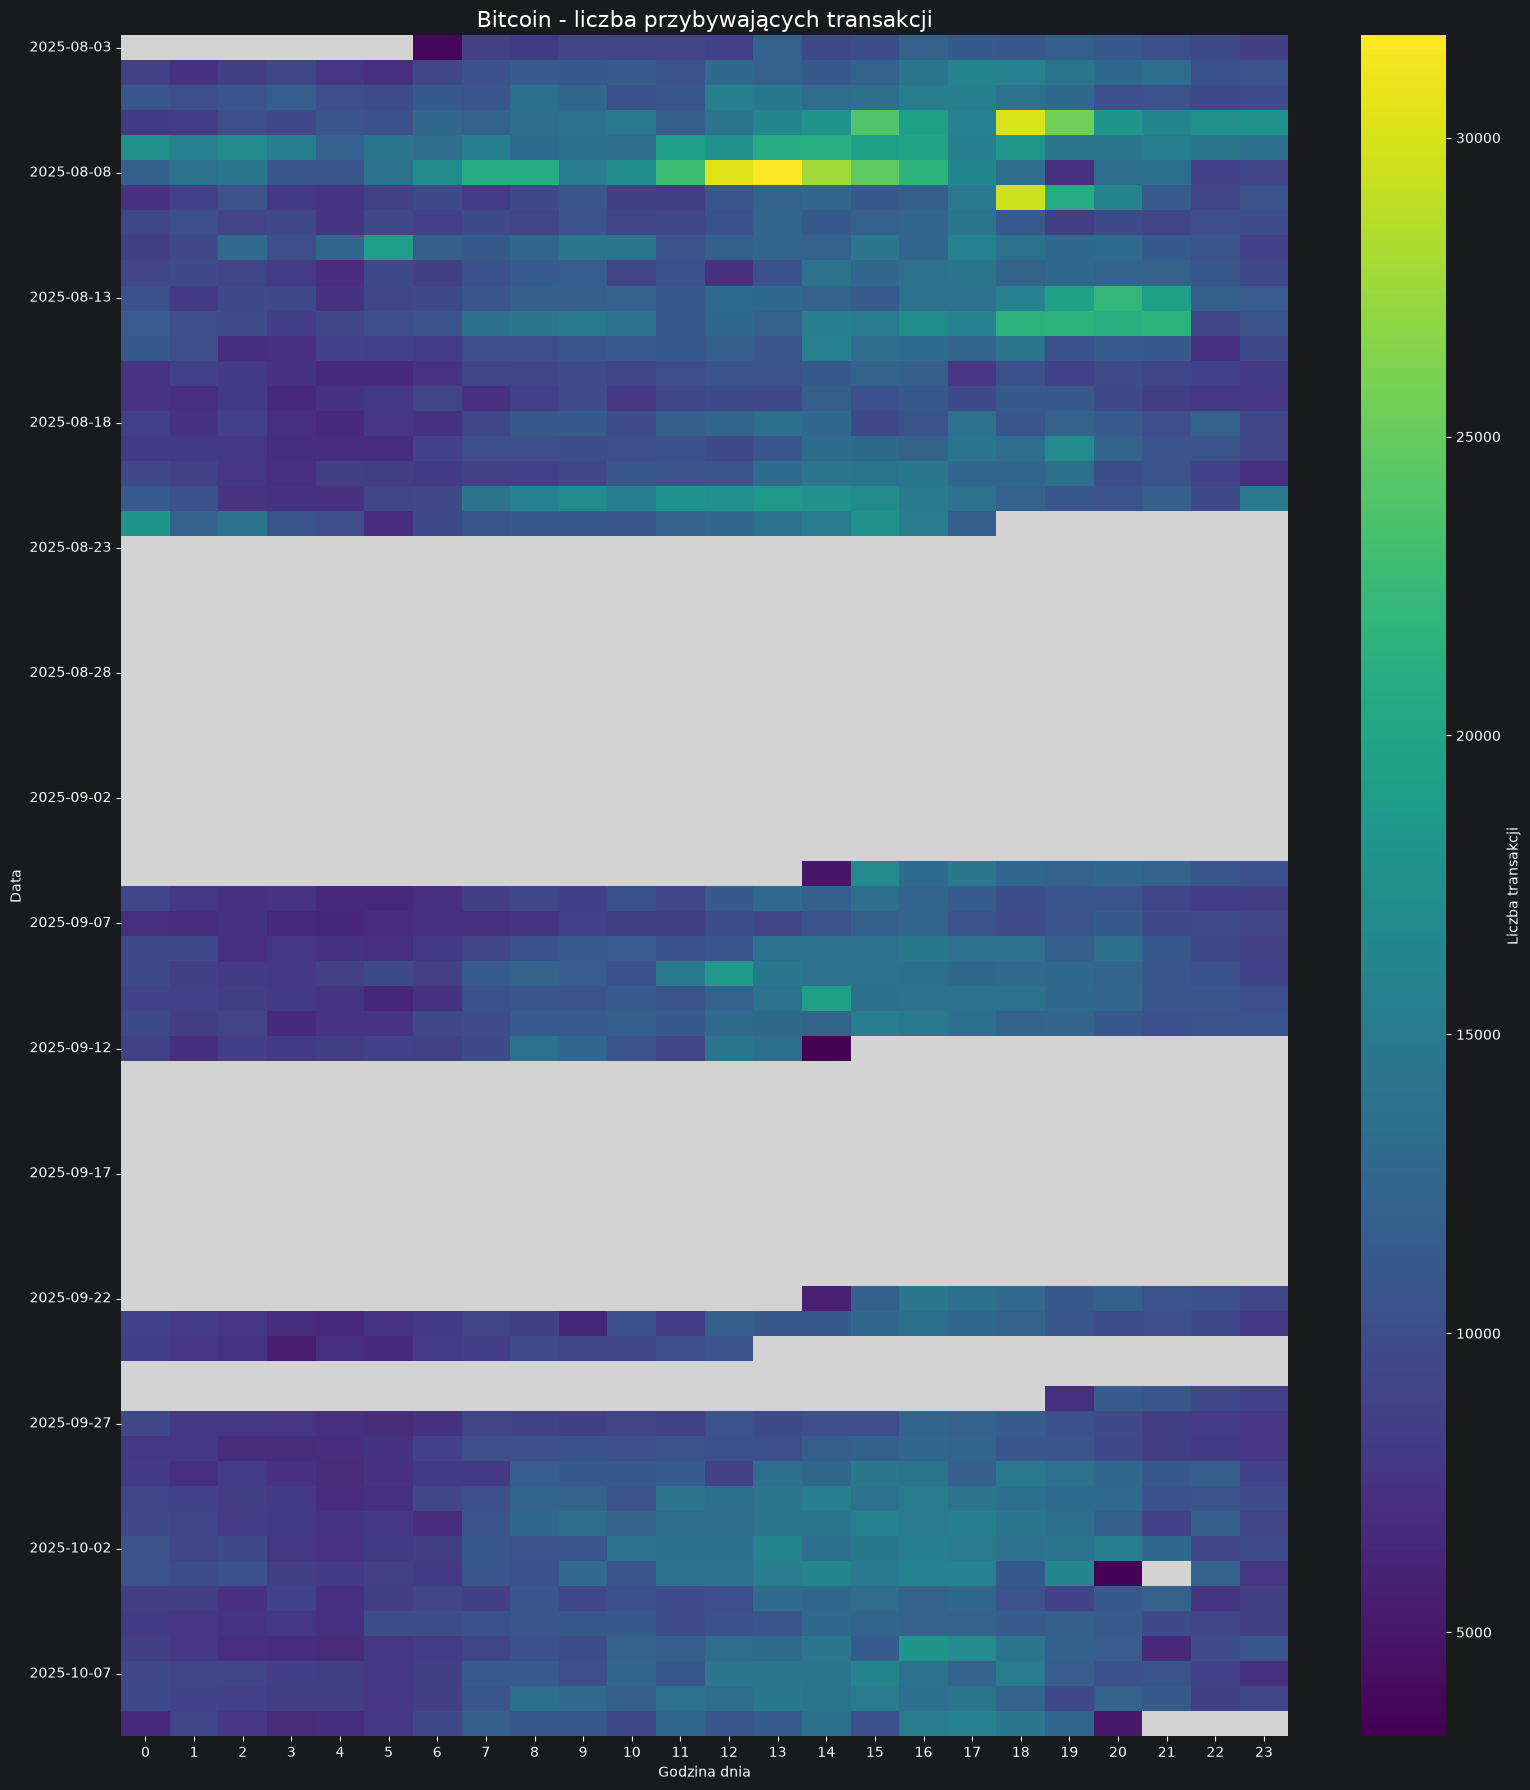

In [152]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Gotowe dane godzinowe
s = ile_transakcji_na_godzine.copy()
s.index = pd.to_datetime(s.index)
s = s.sort_index().dropna()

# Przygotowanie tabeli
df = pd.DataFrame({
    'dzien': s.index.normalize(),
    'godzina': s.index.hour,
    'liczba_transakcji': s.values
})

# Wiersze = dni, kolumny = godziny
heatmap = df.pivot_table(
    index='dzien',
    columns='godzina',
    values='liczba_transakcji',
    aggfunc='sum'
)

# Wszystkie godziny 0-23
heatmap = heatmap.reindex(columns=range(24))

# Wszystkie dni, również bez danych
dni = pd.date_range(
    heatmap.index.min(),
    heatmap.index.max(),
    freq='D'
)
heatmap = heatmap.reindex(dni)

# Kolor dla brakujących obserwacji
cmap = plt.colormaps['viridis'].copy()
cmap.set_bad('lightgray')

# Wykres
fig, ax = plt.subplots(figsize=(16, 18))

sns.heatmap(
    heatmap,
    cmap=cmap,
    cbar_kws={'label': 'Liczba transakcji'},
    ax=ax
)

ax.set_title(
    'Bitcoin - liczba przybywających transakcji',
    fontsize=16
)

ax.set_xlabel('Godzina dnia')
ax.set_ylabel('Data')

# Etykiety co 5 dni
pozycje = np.arange(0, len(heatmap), 5)
ax.set_yticks(pozycje + 0.5)
ax.set_yticklabels(
    heatmap.index[pozycje].strftime('%Y-%m-%d'),
    rotation=0
)

plt.tight_layout()
plt.show()


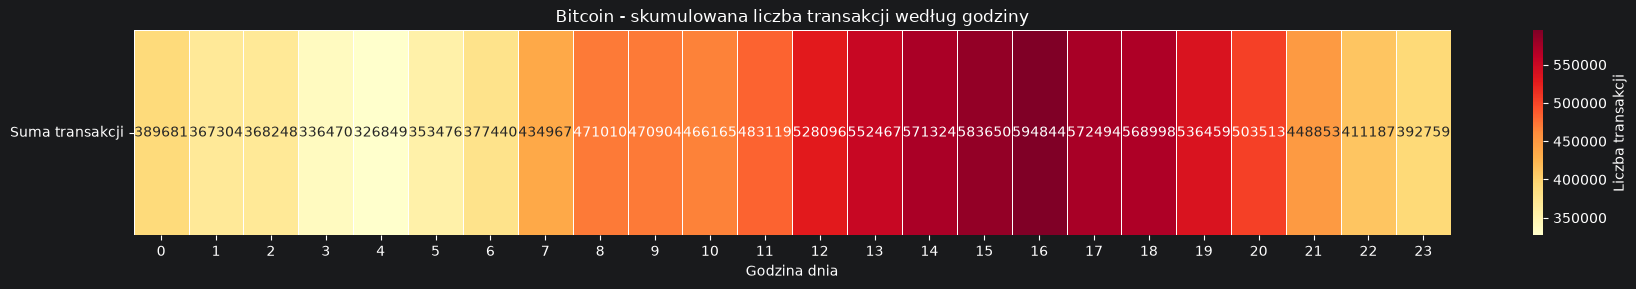

In [153]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Twoje gotowe dane godzinowe
s = ile_transakcji_na_godzine.sort_index()

# Suma transakcji dla każdej godziny doby
suma_godzinowa = (
    s.groupby(s.index.hour)
    .sum(min_count=1)
    .reindex(range(24))
)

# Jeden wiersz heatmapy
heatmap = pd.DataFrame(
    [suma_godzinowa.values],
    index=["Suma transakcji"],
    columns=range(24)
)

plt.figure(figsize=(18, 3))

sns.heatmap(
    heatmap,
    cmap="YlOrRd",
    annot=True,
    fmt=".0f",
    linewidths=0.5,
    cbar_kws={"label": "Liczba transakcji"}
)

plt.xlabel("Godzina dnia")
plt.ylabel("")
plt.title("Bitcoin - skumulowana liczba transakcji według godziny")

plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


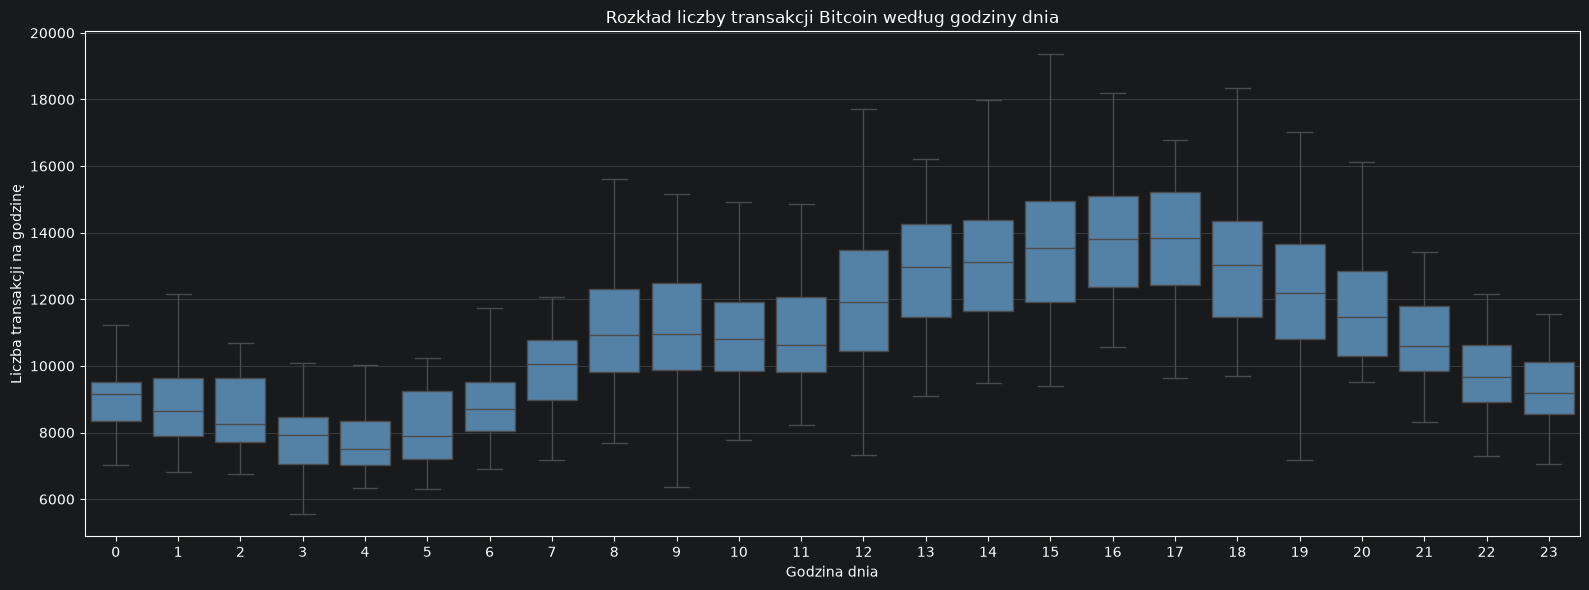

In [156]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gotowe dane godzinowe
s = ile_transakcji_na_godzine.sort_index().dropna()

# Przygotowanie danych
df = pd.DataFrame({
    "godzina": s.index.hour,
    "liczba_transakcji": s.values
})

# Boxplot
plt.figure(figsize=(16, 6))

sns.boxplot(
    data=df,
    x="godzina",
    y="liczba_transakcji",
    order=range(24),
    color="steelblue",
    showfliers=False
)

plt.xlabel("Godzina dnia")
plt.ylabel("Liczba transakcji na godzinę")
plt.title("Rozkład liczby transakcji Bitcoin według godziny dnia")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


,lambda_godzina,liczba_obserwacji,suma_transakcji,lambda_sekunda
found_at,,,,
0,9504.414634,41,389681,2.640115
1,8958.634146,41,367304,2.488509
2,8981.658537,41,368248,2.494905
3,8206.585366,41,336470,2.279607
4,7971.926829,41,326849,2.214424
5,8621.365854,41,353476,2.394824
6,8986.666667,42,377440,2.496296
7,10356.357143,42,434967,2.876766
8,11214.523810,42,471010,3.115146


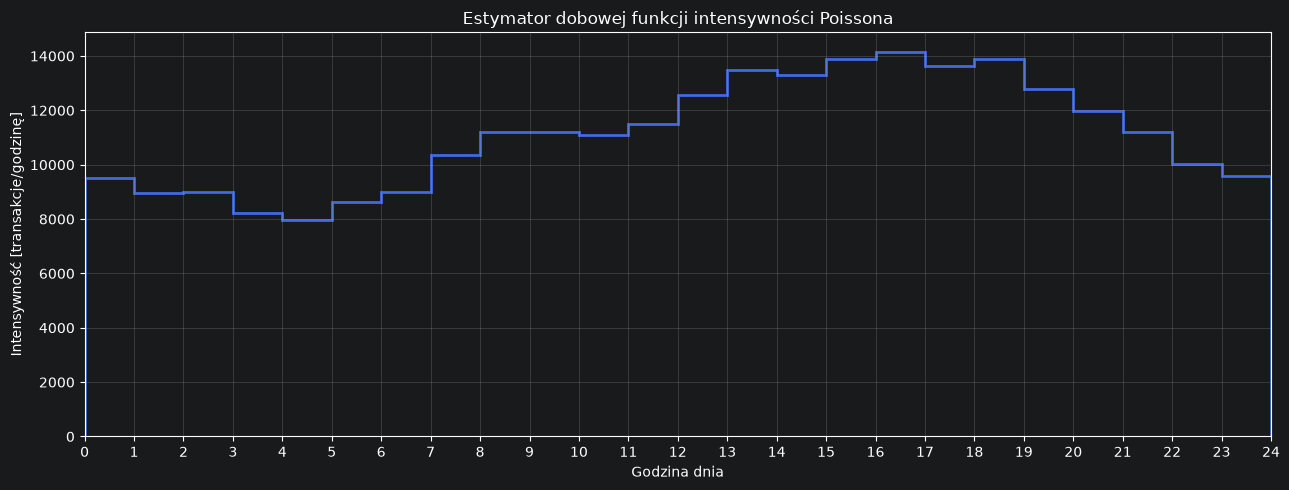

In [157]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Gotowe dane godzinowe
s = ile_transakcji_na_godzine.copy()
s.index = pd.to_datetime(s.index)
s = s.sort_index().dropna()

# Estymacja intensywności w każdej godzinie doby
estymacja = (
    s.groupby(s.index.hour)
    .agg(['mean', 'count', 'sum'])
    .reindex(range(24))
)

estymacja.columns = [
    'lambda_godzina',
    'liczba_obserwacji',
    'suma_transakcji'
]

# Intensywność w transakcjach na sekundę
estymacja['lambda_sekunda'] = (
    estymacja['lambda_godzina'] / 3600
)

display(estymacja)

# Wykres funkcji intensywności
fig, ax = plt.subplots(figsize=(13, 5))

ax.stairs(
    estymacja['lambda_godzina'].values,
    edges=np.arange(25),
    linewidth=2,
    color='royalblue'
)

ax.set_xlabel('Godzina dnia')
ax.set_ylabel('Intensywność [transakcje/godzinę]')
ax.set_title('Estymator dobowej funkcji intensywności Poissona')

ax.set_xticks(range(25))
ax.set_xlim(0, 24)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


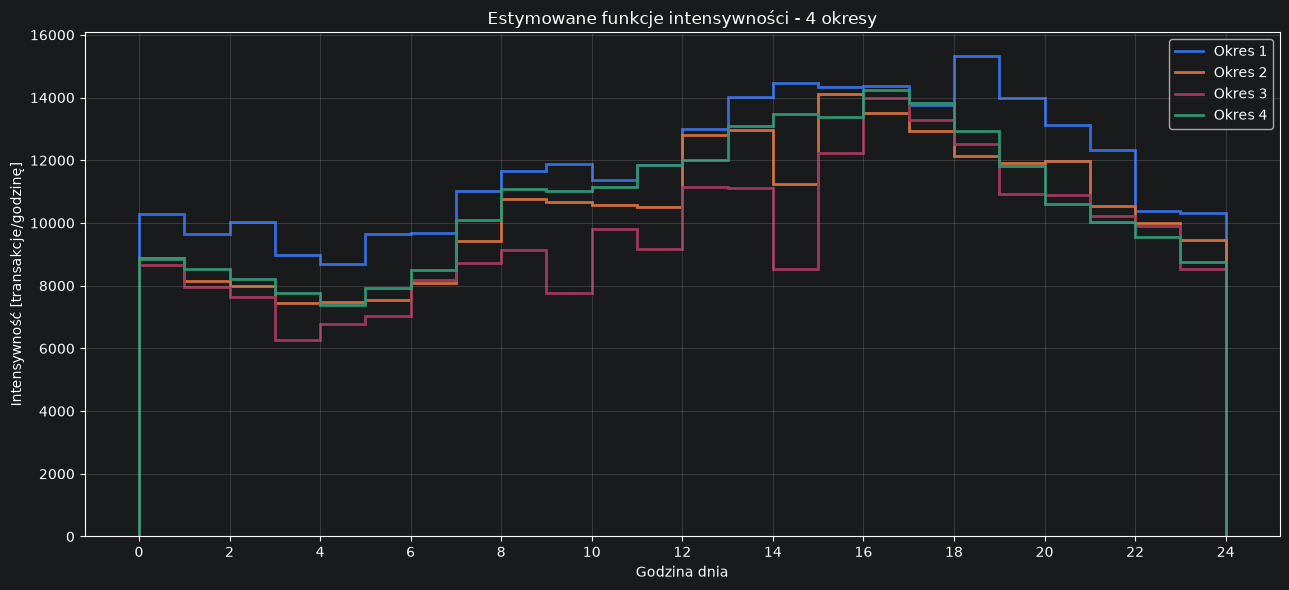

In [158]:
fig, ax = plt.subplots(figsize=(13, 6))

for nazwa, dane in okresy.items():

    profil = (
        dane.groupby(dane.index.hour)
        .mean()
        .reindex(range(24))
    )

    ax.stairs(
        profil.values,
        edges=np.arange(25),
        label=nazwa,
        linewidth=2
    )

ax.set_xlabel('Godzina dnia')
ax.set_ylabel('Intensywność [transakcje/godzinę]')
ax.set_title('Estymowane funkcje intensywności - 4 okresy')
ax.set_xticks(range(0, 25, 2))
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()